In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Detect project root.
# This works both if the notebook is opened from the repo root
# and if it is opened from the notebooks/ folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT exists:", PROJECT_ROOT.exists())
print("configs/req1.yaml exists:", (PROJECT_ROOT / "configs" / "req1.yaml").exists())
print("experiments/run_req1.py exists:", (PROJECT_ROOT / "experiments" / "run_req1.py").exists())
print("ola package exists:", (PROJECT_ROOT / "ola").exists())

PROJECT_ROOT: /Users/foadzahedilabaf/Projects/ola-project
PROJECT_ROOT exists: True
configs/req1.yaml exists: True
experiments/run_req1.py exists: True
ola package exists: True


In [2]:
from ola.environments.single_campaign import SingleCampaignEnvironment
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB

from experiments.run_req1 import (
    load_req1_config,
    compute_req1_benchmarks,
    run_algorithm,
    save_algorithm_results,
)

print("All Req 1 project imports worked correctly.")

All Req 1 project imports worked correctly.


In [3]:
config_path = PROJECT_ROOT / "configs" / "req1.yaml"

config = load_req1_config(config_path)

print("Loaded config from:", config_path)
print("Top-level config keys:")
for key in config.keys():
    print("-", key)

print("\nFull config:")
config

Loaded config from: /Users/foadzahedilabaf/Projects/ola-project/configs/req1.yaml
Top-level config keys:
- experiment
- campaign
- bids
- environment
- outputs

Full config:


{'experiment': {'name': 'req1_single_campaign',
  'random_seed': 42,
  'horizon': 1000},
 'campaign': {'value': 1.0, 'initial_budget': 300.0},
 'bids': {'values': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]},
 'environment': {'competing_bid_distribution': 'uniform',
  'min_competing_bid': 0.0,
  'max_competing_bid': 1.0},
 'outputs': {'results_dir': 'results/raw',
  'ucb1_results_file': 'results/raw/req1_ucb1.csv',
  'budgeted_ucb_results_file': 'results/raw/req1_budgeted_ucb.csv'}}

In [4]:
experiment_config = config["experiment"]
campaign_config = config["campaign"]
bids_config = config["bids"]
environment_config = config["environment"]
outputs_config = config["outputs"]

experiment_name = experiment_config["name"]
random_seed = int(experiment_config["random_seed"])
horizon = int(experiment_config["horizon"])

value = float(campaign_config["value"])
initial_budget = float(campaign_config["initial_budget"])
rho = initial_budget / horizon

bids = np.array(bids_config["values"], dtype=float)

competing_bid_distribution = environment_config["competing_bid_distribution"]
min_competing_bid = float(environment_config["min_competing_bid"])
max_competing_bid = float(environment_config["max_competing_bid"])

print("Experiment name:", experiment_name)
print("Random seed:", random_seed)
print("Horizon T:", horizon)
print("Campaign value v:", value)
print("Initial budget B:", initial_budget)
print("Per-round budget rho = B/T:", rho)
print("Bid set:", bids)
print("Number of bids:", len(bids))
print("Competing bid distribution:", competing_bid_distribution)
print("Competing bid support:", [min_competing_bid, max_competing_bid])

print("\nSanity checks:")
print("T > 0:", horizon > 0)
print("0 <= value <= 1:", 0 <= value <= 1)
print("0 <= initial_budget <= T:", 0 <= initial_budget <= horizon)
print("0 <= rho <= 1:", 0 <= rho <= 1)
print("All bids in [0, 1]:", np.all((bids >= 0) & (bids <= 1)))
print("Bids sorted increasingly:", np.all(np.diff(bids) >= 0))
print("Uniform support valid:", 0 <= min_competing_bid < max_competing_bid <= 1)

Experiment name: req1_single_campaign
Random seed: 42
Horizon T: 1000
Campaign value v: 1.0
Initial budget B: 300.0
Per-round budget rho = B/T: 0.3
Bid set: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
Number of bids: 11
Competing bid distribution: uniform
Competing bid support: [0.0, 1.0]

Sanity checks:
T > 0: True
0 <= value <= 1: True
0 <= initial_budget <= T: True
0 <= rho <= 1: True
All bids in [0, 1]: True
Bids sorted increasingly: True
Uniform support valid: True


In [5]:
def expected_win_probability_uniform(bid, min_bid, max_bid):
    """P(m <= bid) when m ~ Uniform(min_bid, max_bid)."""
    if bid <= min_bid:
        return 0.0 if bid < min_bid else 0.0
    if bid >= max_bid:
        return 1.0
    return (bid - min_bid) / (max_bid - min_bid)


rows = []

for bid in bids:
    win_probability = expected_win_probability_uniform(
        bid=bid,
        min_bid=min_competing_bid,
        max_bid=max_competing_bid,
    )

    expected_reward = (value - bid) * win_probability
    expected_cost = bid * win_probability

    rows.append(
        {
            "bid": bid,
            "win_probability": win_probability,
            "expected_reward": expected_reward,
            "expected_cost": expected_cost,
            "budget_feasible_alone": expected_cost <= rho,
        }
    )

bid_table = pd.DataFrame(rows)

bid_table

,bid,win_probability,expected_reward,expected_cost,budget_feasible_alone
0,0.0,0.0,0.00,0.00,True
1,0.1,0.1,0.09,0.01,True
2,0.2,0.2,0.16,0.04,True
3,0.3,0.3,0.21,0.09,True
4,0.4,0.4,0.24,0.16,True
5,0.5,0.5,0.25,0.25,True
6,0.6,0.6,0.24,0.36,False
7,0.7,0.7,0.21,0.49,False
8,0.8,0.8,0.16,0.64,False
9,0.9,0.9,0.09,0.81,False


In [6]:
reward_only_best_row = bid_table.loc[bid_table["expected_reward"].idxmax()]

feasible_bid_table = bid_table[bid_table["budget_feasible_alone"]]
best_feasible_single_bid_row = feasible_bid_table.loc[
    feasible_bid_table["expected_reward"].idxmax()
]

print("Reward-only best bid")
print("--------------------")
print("bid:", reward_only_best_row["bid"])
print("expected reward:", reward_only_best_row["expected_reward"])
print("expected cost:", reward_only_best_row["expected_cost"])

print("\nBest feasible single bid under rho")
print("----------------------------------")
print("bid:", best_feasible_single_bid_row["bid"])
print("expected reward:", best_feasible_single_bid_row["expected_reward"])
print("expected cost:", best_feasible_single_bid_row["expected_cost"])
print("rho:", rho)

Reward-only best bid
--------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25

Best feasible single bid under rho
----------------------------------
bid: 0.5
expected reward: 0.25
expected cost: 0.25
rho: 0.3


In [7]:
env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

initial_state = env.reset()

print("Initial state:")
print(initial_state)

Initial state:
{'round': 0, 'budget_left': 300.0, 'done': False, 'info': {'value': 1.0, 'horizon': 1000, 'min_competing_bid': 0.0, 'max_competing_bid': 1.0}}


**Note on budget clipping.** When the remaining budget is smaller than the selected bid, 
the environment clips the effective bid to `min(bid, budget_left)`. This ensures the 
budget never becomes negative without needing an explicit early-stop threshold. 
The learner is always updated using the originally selected bid (not the clipped value), 
so the action set remains consistent throughout the run.
Note that the learner's value estimate for the originally selected bid is therefore based on the realized (clipped) cost/reward, which is a deliberate simplification — a stricter alternative would mask unaffordable bids out of the learner's action set entirely.

In [8]:
test_env = SingleCampaignEnvironment(
    value=value,
    initial_budget=initial_budget,
    horizon=10,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    random_seed=random_seed,
)

test_env.reset()

test_bids = [0.0, 0.2, 0.5, 0.8, 1.0]
test_rows = []

for bid in test_bids:
    outcome = test_env.step(bid)

    highest_competing_bid = outcome["info"]["highest_competing_bid"]
    win = outcome["wins"]
    reward = outcome["reward"]
    cost = outcome["cost"]

    manually_expected_win = int(bid >= highest_competing_bid)
    manually_expected_reward = float(value - bid) if manually_expected_win else 0.0
    manually_expected_cost = float(bid) if manually_expected_win else 0.0

    test_rows.append(
        {
            "round": outcome["round"],
            "bid": bid,
            "highest_competing_bid": highest_competing_bid,
            "win": win,
            "reward": reward,
            "cost": cost,
            "budget_left": outcome["budget_left"],
            "manual_win_check": win == manually_expected_win,
            "manual_reward_check": np.isclose(reward, manually_expected_reward),
            "manual_cost_check": np.isclose(cost, manually_expected_cost),
        }
    )

step_check_table = pd.DataFrame(test_rows)
step_check_table

,round,bid,highest_competing_bid,win,reward,cost,budget_left,manual_win_check,manual_reward_check,manual_cost_check
0,1,0.0,0.773956,0,0.0,0.0,300.0,True,True,True
1,2,0.2,0.438878,0,0.0,0.0,300.0,True,True,True
2,3,0.5,0.858598,0,0.0,0.0,300.0,True,True,True
3,4,0.8,0.697368,1,0.2,0.8,299.2,True,True,True
4,5,1.0,0.094177,1,0.0,1.0,298.2,True,True,True


In [9]:
ucb1_benchmark, budgeted_ucb_benchmark = compute_req1_benchmarks(
    bids=bids,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
)

print("Official UCB1 benchmark per round:", ucb1_benchmark)
print("Official Budgeted UCB benchmark per round:", budgeted_ucb_benchmark)

print("\nManual reward-only best expected reward:", reward_only_best_row["expected_reward"])
print("Manual best feasible single-bid expected reward:", best_feasible_single_bid_row["expected_reward"])

Official UCB1 benchmark per round: 0.25
Official Budgeted UCB benchmark per round: 0.25

Manual reward-only best expected reward: 0.25
Manual best feasible single-bid expected reward: 0.25


In [10]:
ucb1_debug = UCB1(actions=bids, horizon=horizon)

ucb1_debug_rows = []

# UCB1 should first try every bid once.
for step in range(len(bids)):
    selected_action = ucb1_debug.select_action()

    # Give a fake reward only to test whether counts and updates work.
    fake_reward = 1.0 - selected_action

    ucb1_debug.update(action=selected_action, reward=fake_reward)

    ucb1_debug_rows.append(
        {
            "step": step + 1,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "counts_after_update": ucb1_debug.counts.copy(),
            "total_rewards_after_update": ucb1_debug.total_rewards.copy(),
        }
    )

ucb1_debug_table = pd.DataFrame(ucb1_debug_rows)

print("Final counts after initial exploration:")
print(ucb1_debug.counts)

ucb1_debug_table[["step", "selected_action", "fake_reward"]]

Final counts after initial exploration:
[1 1 1 1 1 1 1 1 1 1 1]


,step,selected_action,fake_reward
0,1,0.0,1.0
1,2,0.1,0.9
2,3,0.2,0.8
3,4,0.3,0.7
4,5,0.4,0.6
5,6,0.5,0.5
6,7,0.6,0.4
7,8,0.7,0.3
8,9,0.8,0.2
9,10,0.9,0.1


In [11]:
budgeted_ucb_debug = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_debug_rows = []

# Test one update for each bid, using fake reward and fake cost.
# This checks that BudgetedUCB updates both reward and cost estimates.
for step, selected_action in enumerate(bids, start=1):
    fake_reward = 1.0 - selected_action
    fake_cost = selected_action

    budgeted_ucb_debug.update(
        action=selected_action,
        reward=fake_reward,
        cost=fake_cost,
    )

    budgeted_ucb_debug_rows.append(
        {
            "step": step,
            "selected_action": selected_action,
            "fake_reward": fake_reward,
            "fake_cost": fake_cost,
        }
    )

budgeted_ucb_debug_table = pd.DataFrame(budgeted_ucb_debug_rows)

print("Counts after one fake update per bid:")
print(budgeted_ucb_debug.counts)

print("\nTotal rewards after fake updates:")
print(budgeted_ucb_debug.total_rewards)

print("\nTotal costs after fake updates:")
print(budgeted_ucb_debug.total_costs)

print("\nBudget left after fake updates:")
print(budgeted_ucb_debug.budget_left)

budgeted_ucb_debug_table

Counts after one fake update per bid:
[1 1 1 1 1 1 1 1 1 1 1]

Total rewards after fake updates:
[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.2 0.1 0. ]

Total costs after fake updates:
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]

Budget left after fake updates:
294.5


,step,selected_action,fake_reward,fake_cost
0,1,0.0,1.0,0.0
1,2,0.1,0.9,0.1
2,3,0.2,0.8,0.2
3,4,0.3,0.7,0.3
4,5,0.4,0.6,0.4
5,6,0.5,0.5,0.5
6,7,0.6,0.4,0.6
7,8,0.7,0.3,0.7
8,9,0.8,0.2,0.8
9,10,0.9,0.1,0.9


In [12]:
ucb1 = UCB1(actions=bids, horizon=horizon)

ucb1_rows = run_algorithm(
    algorithm_name="ucb1",
    learner=ucb1,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=ucb1_benchmark,
)

ucb1_df = pd.DataFrame(ucb1_rows)

print("Number of rows:", len(ucb1_df))
print("First rows:")
display(ucb1_df.head())

print("\nLast rows:")
display(ucb1_df.tail())

Number of rows: 936
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
931,ucb1,932,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.30,0.371253,False,0.3
932,ucb1,933,0.2,0.2,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.55,0.404855,False,0.2
933,ucb1,934,0.3,0.3,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,64.80,0.760015,False,0.3
934,ucb1,935,0.7,0.7,0,0.0,0.0,0.7,168.7,299.3,0.25,0.25,65.05,0.772353,False,0.7
935,ucb1,936,0.9,0.9,1,0.3,0.7,0.0,169.0,300.0,0.25,-0.05,65.00,0.206814,True,0.7


In [13]:
required_columns = [
    "algorithm",
    "round",
    "action",
    "bids",
    "wins",
    "reward",
    "cost",
    "budget_left",
    "cumulative_reward",
    "cumulative_cost",
    "benchmark_reward",
    "instant_regret",
    "cumulative_regret",
]

missing_columns = [col for col in required_columns if col not in ucb1_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(ucb1_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(ucb1_df["round"].min()))
print("last round:", int(ucb1_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(ucb1_df["budget_left"].min()))
print("final budget_left:", float(ucb1_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(ucb1_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((ucb1_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(ucb1_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(ucb1_df["done"].iloc[-1]))
print("stopped early:", len(ucb1_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['ucb1']
Length: 1, dtype: str

Round range:
first round: 1
last round: 936

Budget checks:
minimum budget_left: 0.0
final budget_left: 0.0
final cumulative_cost: 299.9999999999997
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: True


In [14]:
budgeted_ucb = BudgetedUCB(
    actions=bids,
    horizon=horizon,
    initial_budget=initial_budget,
)

budgeted_ucb_rows = run_algorithm(
    algorithm_name="budgeted_ucb",
    learner=budgeted_ucb,
    value=value,
    initial_budget=initial_budget,
    horizon=horizon,
    random_seed=random_seed,
    min_competing_bid=min_competing_bid,
    max_competing_bid=max_competing_bid,
    benchmark_reward_per_round=budgeted_ucb_benchmark,
)

budgeted_ucb_df = pd.DataFrame(budgeted_ucb_rows)

print("Number of rows:", len(budgeted_ucb_df))
print("First rows:")
display(budgeted_ucb_df.head())

print("\nLast rows:")
display(budgeted_ucb_df.tail())

Number of rows: 1000
First rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,budgeted_ucb,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,budgeted_ucb,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,budgeted_ucb,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,budgeted_ucb,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,budgeted_ucb,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4



Last rows:


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
995,budgeted_ucb,996,0.2,0.2,0,0.0,0.0,1.4,177.4,298.6,0.25,0.25,71.60,0.437990,False,0.2
996,budgeted_ucb,997,0.7,0.7,1,0.3,0.7,0.7,177.7,299.3,0.25,-0.05,71.55,0.639014,False,0.7
997,budgeted_ucb,998,0.4,0.4,1,0.6,0.4,0.3,178.3,299.7,0.25,-0.35,71.20,0.002309,False,0.4
998,budgeted_ucb,999,0.3,0.3,0,0.0,0.0,0.3,178.3,299.7,0.25,0.25,71.45,0.993368,False,0.3
999,budgeted_ucb,1000,0.2,0.2,0,0.0,0.0,0.3,178.3,299.7,0.25,0.25,71.70,0.280896,True,0.2


In [15]:
missing_columns = [col for col in required_columns if col not in budgeted_ucb_df.columns]

print("Missing required columns:", missing_columns)
print("All required columns present:", len(missing_columns) == 0)

print("\nAlgorithm values:")
print(budgeted_ucb_df["algorithm"].unique())

print("\nRound range:")
print("first round:", int(budgeted_ucb_df["round"].min()))
print("last round:", int(budgeted_ucb_df["round"].max()))

print("\nBudget checks:")
print("minimum budget_left:", float(budgeted_ucb_df["budget_left"].min()))
print("final budget_left:", float(budgeted_ucb_df["budget_left"].iloc[-1]))
print("final cumulative_cost:", float(budgeted_ucb_df["cumulative_cost"].iloc[-1]))
print("initial_budget:", initial_budget)
print("budget never negative:", bool((budgeted_ucb_df["budget_left"] >= -1e-9).all()))
print("cumulative cost within budget:", bool(budgeted_ucb_df["cumulative_cost"].iloc[-1] <= initial_budget + 1e-9))

print("\nStopping check:")
print("last done value:", bool(budgeted_ucb_df["done"].iloc[-1]))
print("stopped early:", len(budgeted_ucb_df) < horizon)

Missing required columns: []
All required columns present: True

Algorithm values:
<StringArray>
['budgeted_ucb']
Length: 1, dtype: str

Round range:
first round: 1
last round: 1000

Budget checks:
minimum budget_left: 0.3000000000001136
final budget_left: 0.3000000000001136
final cumulative_cost: 299.6999999999997
initial_budget: 300.0
budget never negative: True
cumulative cost within budget: True

Stopping check:
last done value: True
stopped early: False


## Analytical derivation: optimal bid and critical budget threshold

For competing bids $m \sim \text{Uniform}(0, 1)$ and value $v = 1$, each bid $b \in [0,1]$ produces:

$$\bar{f}(b) = \mathbb{E}[\text{reward} \mid b] = (v - b) \cdot \Pr[b \geq m] = (1 - b) \cdot b$$

$$\bar{c}(b) = \mathbb{E}[\text{cost} \mid b] = b \cdot \Pr[b \geq m] = b^2$$

**Unconstrained optimum.** Taking the derivative and setting to zero:

$$\frac{d}{db}\bar{f}(b) = 1 - 2b = 0 \implies b^* = 0.5, \quad \bar{f}(b^*) = 0.25$$

**Critical budget threshold.** The budget constraint $\bar{c}(b^*) \leq \rho$ becomes:

$$b^{*2} = 0.25 \leq \rho$$

So the constraint is **non-binding** if and only if $\rho \geq 0.25$.  
In our experiment, $\rho = B/T = 300/1000 = 0.30 > 0.25$, so $b^* = 0.5$ remains feasible — UCB1 and Budgeted UCB converge to the same optimum.  
This also explains the tight-budget stress test: at $B = 150$, $\rho = 0.15 < 0.25$,
forcing a lower bid and making the budget constraint binding — UCB1 depletes the budget
by round ~480 while Budgeted UCB reaches the full horizon. Note that even in the official
configuration ($B=300$, $\rho=0.30 > 0.25$), UCB1 still exhausts its budget before T=1000
in practice (around round 936 in this run), since UCB1's bidding rule has no mechanism to
slow spending as the budget approaches zero — it simply stops once funds run out.

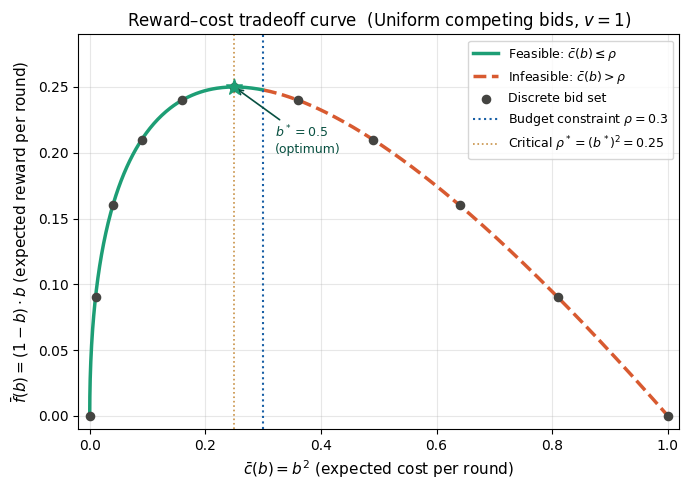

In [16]:
 # Reward–cost tradeoff curve: geometric view of the LP from Part 8
b_cont = np.linspace(0.001, 0.999, 500)
E_cost_cont = b_cont ** 2
E_reward_cont = (1 - b_cont) * b_cont

rho_critical = 0.5 ** 2  # = 0.25

fig, ax = plt.subplots(figsize=(7, 5))

# Split curve into feasible (green) and infeasible (red dashed) parts
feasible_mask = E_cost_cont <= rho
ax.plot(E_cost_cont[feasible_mask], E_reward_cont[feasible_mask],
        color="#1D9E75", lw=2.5, label="Feasible: $\\bar{c}(b) \\leq \\rho$")
ax.plot(E_cost_cont[~feasible_mask], E_reward_cont[~feasible_mask],
        color="#D85A30", lw=2.5, linestyle="--", label="Infeasible: $\\bar{c}(b) > \\rho$")

# Discrete bids from config
E_cost_d = bids ** 2
E_reward_d = (1 - bids) * bids
ax.scatter(E_cost_d, E_reward_d, color="#444441", s=35, zorder=5, label="Discrete bid set")

# Budget constraint line and critical threshold
ax.axvline(x=rho, color="#185FA5", lw=1.5, linestyle=":",
           label=f"Budget constraint $\\rho = {rho}$")
ax.axvline(x=rho_critical, color="#BA7517", lw=1.2, linestyle=":", alpha=0.8,
           label=f"Critical $\\rho^* = (b^*)^2 = {rho_critical}$")

# Optimal point b*=0.5
ax.scatter([0.25], [0.25], color="#1D9E75", s=140, zorder=6, marker="*")
ax.annotate("$b^* = 0.5$\n(optimum)", xy=(0.25, 0.25), xytext=(0.32, 0.20),
            fontsize=9, color="#085041",
            arrowprops=dict(arrowstyle="->", color="#085041", lw=1.2))

ax.set_xlabel("$\\bar{c}(b) = b^2$ (expected cost per round)", fontsize=11)
ax.set_ylabel("$\\bar{f}(b) = (1-b) \\cdot b$ (expected reward per round)", fontsize=11)
ax.set_title("Reward–cost tradeoff curve  (Uniform competing bids, $v = 1$)", fontsize=12)
ax.legend(fontsize=9, loc="upper right")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.01, 0.29)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "plots" / "req1_reward_cost_tradeoff.png", dpi=150)
plt.show()

In [17]:
comparison_summary = pd.DataFrame(
    [
        {
            "algorithm": "ucb1",
            "rounds_played": len(ucb1_df),
            "final_round": int(ucb1_df["round"].iloc[-1]),
            "total_reward": float(ucb1_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(ucb1_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(ucb1_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(ucb1_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(ucb1_df) < horizon,
        },
        {
            "algorithm": "budgeted_ucb",
            "rounds_played": len(budgeted_ucb_df),
            "final_round": int(budgeted_ucb_df["round"].iloc[-1]),
            "total_reward": float(budgeted_ucb_df["cumulative_reward"].iloc[-1]),
            "total_cost": float(budgeted_ucb_df["cumulative_cost"].iloc[-1]),
            "final_budget_left": float(budgeted_ucb_df["budget_left"].iloc[-1]),
            "final_cumulative_regret": float(budgeted_ucb_df["cumulative_regret"].iloc[-1]),
            "stopped_early": len(budgeted_ucb_df) < horizon,
        },
    ]
)

comparison_summary

,algorithm,rounds_played,final_round,total_reward,total_cost,final_budget_left,final_cumulative_regret,stopped_early
0,ucb1,936,936,169.0,300.0,0.0,65.0,True
1,budgeted_ucb,1000,1000,178.3,299.7,0.3,71.7,False


## Comparison of UCB1 and Budgeted UCB

The plain UCB1 learner ignores the budget constraint when selecting bids. In this run,
it exhausts the entire $300 budget by round 936 and the episode ends early — it never
reaches the full $T=1000$ horizon, because nothing in its bidding rule slows down spending
as the budget runs low.

Budgeted UCB, by contrast, reaches the full horizon while using almost all of the budget.
It finishes with about $0.3$ budget left, so it respects the budget constraint without
ending the campaign early.

Total reward in this single-seed run:

- UCB1 total reward: 169.0 over 936 rounds.
- Budgeted UCB total reward: 178.3 over 1000 rounds.

Budgeted UCB earns more total reward here because it paces spending and remains active
until the final round. This is the core practical advantage of the budget-aware method:
it avoids spending the budget too early.

**A note on comparing cumulative regret directly.** The table above shows Budgeted UCB
with higher raw cumulative regret than UCB1, even though Budgeted UCB also earns more
total reward. This happens because the two algorithms are evaluated over different
numbers of played rounds in the single-seed run.

UCB1 stops after 936 rounds because it exhausts the budget. Budgeted UCB plays all
1000 rounds, so it has more opportunities to accumulate regret relative to the
per-round benchmark.

Using the table values:

$$
\text{UCB1: } 65.0 / 936 \approx 0.0694 \text{ per played round}
$$

$$
\text{Budgeted UCB: } 71.7 / 1000 = 0.0717 \text{ per played round}
$$

So the per-round values are very close. The main difference is that Budgeted UCB keeps
the campaign alive until the final round, while UCB1 stops early after exhausting the
budget.

In [18]:
ucb1_path = save_algorithm_results(
    ucb1_rows,
    PROJECT_ROOT / outputs_config["ucb1_results_file"],
)

budgeted_ucb_path = save_algorithm_results(
    budgeted_ucb_rows,
    PROJECT_ROOT / outputs_config["budgeted_ucb_results_file"],
)

print("UCB1 CSV path:", ucb1_path)
print("Budgeted UCB CSV path:", budgeted_ucb_path)
print("UCB1 CSV exists:", ucb1_path.exists())
print("Budgeted UCB CSV exists:", budgeted_ucb_path.exists())

Saved 936 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Saved 1000 rows to /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_ucb1.csv
Budgeted UCB CSV path: /Users/foadzahedilabaf/Projects/ola-project/results/raw/req1_budgeted_ucb.csv
UCB1 CSV exists: True
Budgeted UCB CSV exists: True


In [19]:
from ola.utils.plotting import load_result_csvs

combined_results = load_result_csvs([ucb1_path, budgeted_ucb_path])

print("Combined results shape:", combined_results.shape)
print("Algorithms in combined results:")
print(combined_results["algorithm"].value_counts())

display(combined_results.head())
display(combined_results.tail())

Combined results shape: (1936, 16)
Algorithms in combined results:
algorithm
budgeted_ucb    1000
ucb1             936
Name: count, dtype: int64


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
0,ucb1,1,0.0,0.0,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.25,0.773956,False,0.0
1,ucb1,2,0.1,0.1,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.50,0.438878,False,0.1
2,ucb1,3,0.2,0.2,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,0.75,0.858598,False,0.2
3,ucb1,4,0.3,0.3,0,0.0,0.0,300.0,0.0,0.0,0.25,0.25,1.00,0.697368,False,0.3
4,ucb1,5,0.4,0.4,1,0.6,0.4,299.6,0.6,0.4,0.25,-0.35,0.65,0.094177,False,0.4


,algorithm,round,action,bids,wins,reward,cost,budget_left,cumulative_reward,cumulative_cost,benchmark_reward,instant_regret,cumulative_regret,highest_competing_bid,done,effective_bid
1931,budgeted_ucb,996,0.2,0.2,0,0.0,0.0,1.4,177.4,298.6,0.25,0.25,71.60,0.437990,False,0.2
1932,budgeted_ucb,997,0.7,0.7,1,0.3,0.7,0.7,177.7,299.3,0.25,-0.05,71.55,0.639014,False,0.7
1933,budgeted_ucb,998,0.4,0.4,1,0.6,0.4,0.3,178.3,299.7,0.25,-0.35,71.20,0.002309,False,0.4
1934,budgeted_ucb,999,0.3,0.3,0,0.0,0.0,0.3,178.3,299.7,0.25,0.25,71.45,0.993368,False,0.3
1935,budgeted_ucb,1000,0.2,0.2,0,0.0,0.0,0.3,178.3,299.7,0.25,0.25,71.70,0.280896,True,0.2


Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_reward.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_budget_left.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_cumulative_cost.png
Saved plot to /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_selected_bid.png


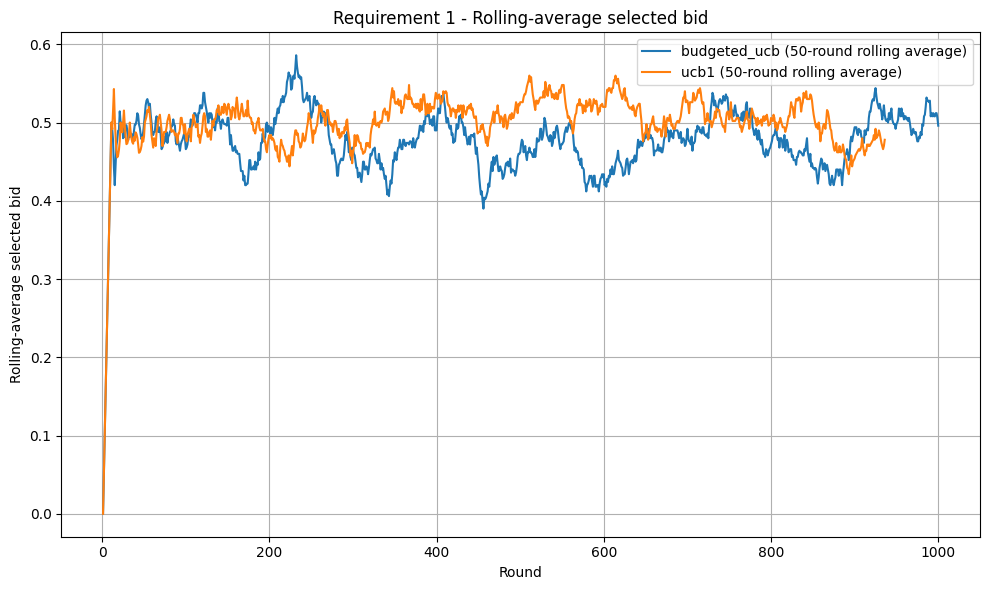

Plots directory: /Users/foadzahedilabaf/Projects/ola-project/results/plots
req1_cumulative_reward.png exists: True
req1_budget_left.png exists: True
req1_cumulative_cost.png exists: True
req1_selected_bid.png exists: True
req1_rolling_average_selected_bid.png exists: True


In [20]:
from ola.utils.plotting import generate_standard_req1_plots

plots_dir = PROJECT_ROOT / "results" / "plots"

# Generate the standard project plots.
generate_standard_req1_plots(
    dataframe=combined_results,
    plots_dir=plots_dir,
)

# Add an extra readability plot for selected bids.
# The raw selected-bid plot is correct, but very noisy because it shows every action.
rolling_window = 50

plt.figure(figsize=(10, 6))

for algorithm_name, group in combined_results.groupby("algorithm"):
    sorted_group = group.sort_values("round").copy()
    sorted_group["rolling_average_bid"] = (
        sorted_group["action"]
        .rolling(window=rolling_window, min_periods=1)
        .mean()
    )

    plt.plot(
        sorted_group["round"],
        sorted_group["rolling_average_bid"],
        label=f"{algorithm_name} ({rolling_window}-round rolling average)",
    )

plt.xlabel("Round")
plt.ylabel("Rolling-average selected bid")
plt.title("Requirement 1 - Rolling-average selected bid")
plt.legend()
plt.grid(True)
plt.tight_layout()

rolling_bid_plot_path = plots_dir / "req1_rolling_average_selected_bid.png"
plt.savefig(rolling_bid_plot_path, dpi=200)
plt.show()

expected_plot_files = [
    "req1_cumulative_reward.png",
    "req1_budget_left.png",
    "req1_cumulative_cost.png",
    "req1_selected_bid.png",
    "req1_rolling_average_selected_bid.png",
]

print("Plots directory:", plots_dir)

for filename in expected_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_cumulative_reward.png


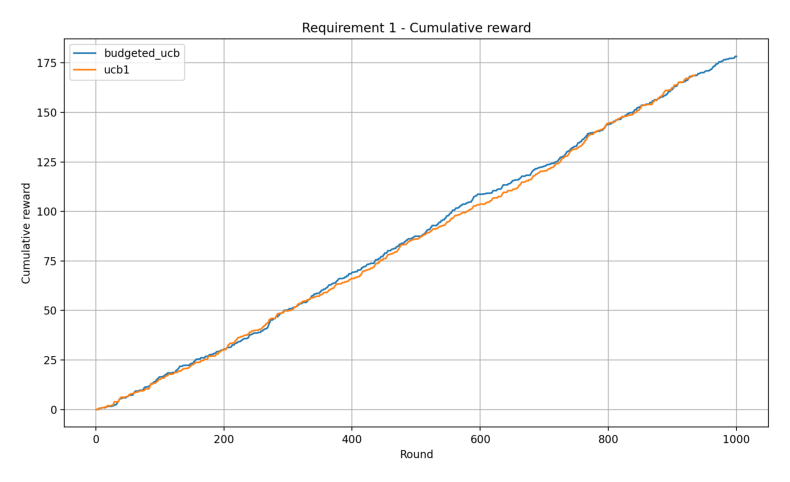

req1_budget_left.png


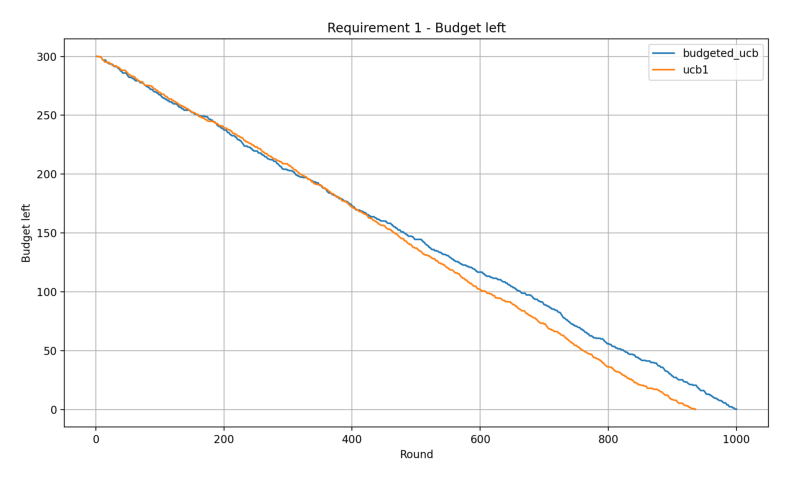

req1_cumulative_cost.png


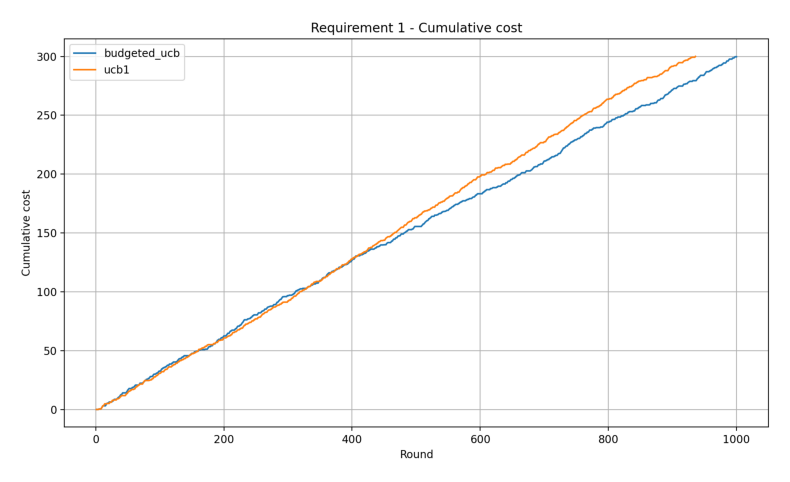

req1_selected_bid.png


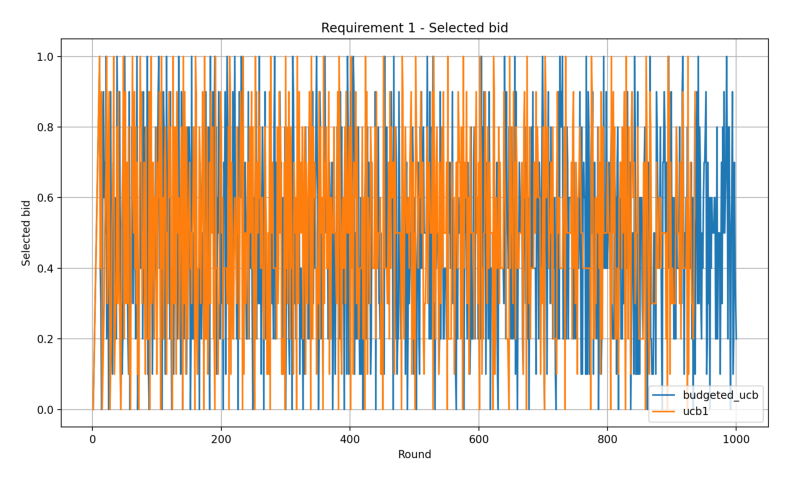

req1_rolling_average_selected_bid.png


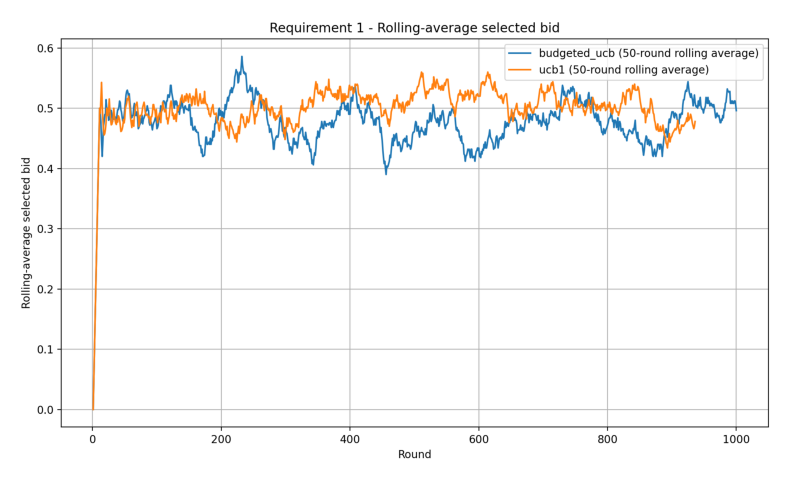

In [21]:
plot_paths = [
    plots_dir / "req1_cumulative_reward.png",
    plots_dir / "req1_budget_left.png",
    plots_dir / "req1_cumulative_cost.png",
    plots_dir / "req1_selected_bid.png",
    plots_dir / "req1_rolling_average_selected_bid.png",
]

for plot_path in plot_paths:
    print(plot_path.name)
    img = plt.imread(plot_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

The cumulative reward plot shows that both algorithms obtain reasonable reward in the
official configuration, but Budgeted UCB finishes with higher total reward because it
remains active until the final round.

The budget-left and cumulative-cost plots show the main behavioral difference between
the two algorithms. UCB1 spends aggressively because it ignores the remaining budget
when selecting bids. As a result, it exhausts the budget before the full horizon and
the episode stops early.

Budgeted UCB controls spending more carefully. It uses the remaining budget and the
number of remaining rounds to pace its bids, so it reaches round $T=1000$ while still
using almost all of the available budget.

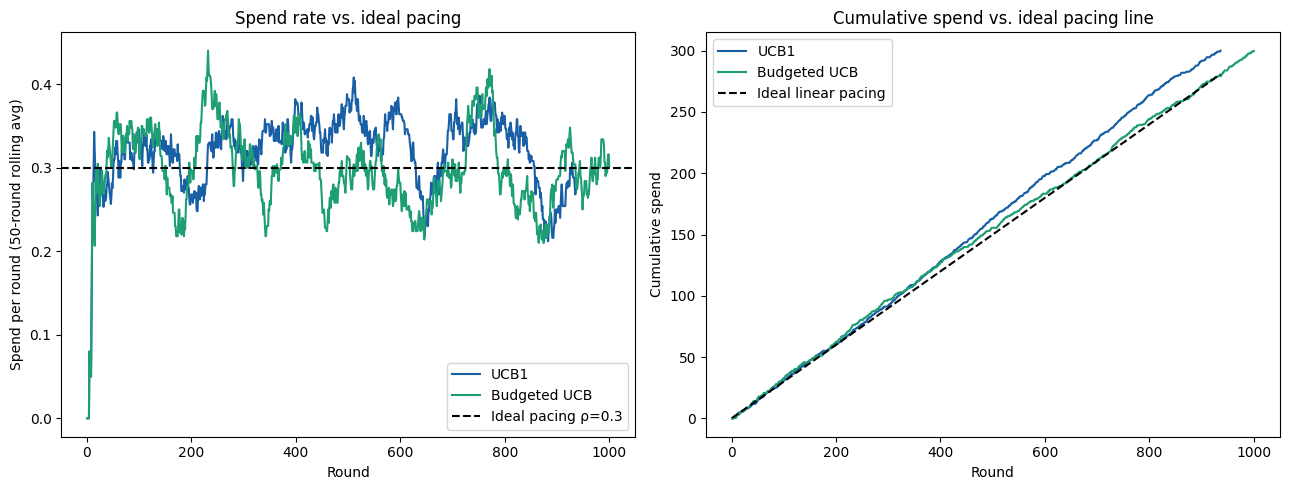

Mean absolute pacing error — UCB1: 10.851
Mean absolute pacing error — Budgeted UCB: 3.205


In [22]:
# ── Budget pacing: spend rate vs. ideal linear pacing ───────────────────────
rho_ideal = initial_budget / horizon
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    rolling_spend = df["cost"].rolling(window=50, min_periods=1).mean()
    axes[0].plot(df["round"], rolling_spend, label=name, color=color)
axes[0].axhline(rho_ideal, color="black", linestyle="--", label=f"Ideal pacing ρ={rho_ideal}")
axes[0].set_xlabel("Round")
axes[0].set_ylabel("Spend per round (50-round rolling avg)")
axes[0].set_title("Spend rate vs. ideal pacing")
axes[0].legend()

for df, name, color in [(ucb1_df, "UCB1", "#185FA5"), (budgeted_ucb_df, "Budgeted UCB", "#1D9E75")]:
    axes[1].plot(df["round"], df["cumulative_cost"], label=name, color=color)
axes[1].plot(ucb1_df["round"], rho_ideal * ucb1_df["round"], "k--", label="Ideal linear pacing")
axes[1].set_xlabel("Round")
axes[1].set_ylabel("Cumulative spend")
axes[1].set_title("Cumulative spend vs. ideal pacing line")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_budget_pacing.png", dpi=200)
plt.show()

pacing_error_ucb1 = (ucb1_df["cumulative_cost"] - rho_ideal * ucb1_df["round"]).abs().mean()
pacing_error_budgeted = (budgeted_ucb_df["cumulative_cost"] - rho_ideal * budgeted_ucb_df["round"]).abs().mean()
print("Mean absolute pacing error — UCB1:", round(pacing_error_ucb1, 3))
print("Mean absolute pacing error — Budgeted UCB:", round(pacing_error_budgeted, 3))

## Additional robustness experiments: multiple seeds and tighter budget

The previous experiment uses one fixed random seed. This is useful for debugging and reproducibility, but the environment is stochastic. A stronger empirical evaluation repeats the experiment over multiple independent seeds.

In this section, we run both algorithms over several random seeds and report mean and standard deviation. We do this for two settings:

1. the official project configuration, with budget `B = 300`;
2. a tighter-budget stress test, with budget `B = 150`.

The stress test is not a replacement for the official configuration. It is an additional diagnostic experiment that makes the budget constraint more binding and helps us understand when budget-aware learning becomes more important.

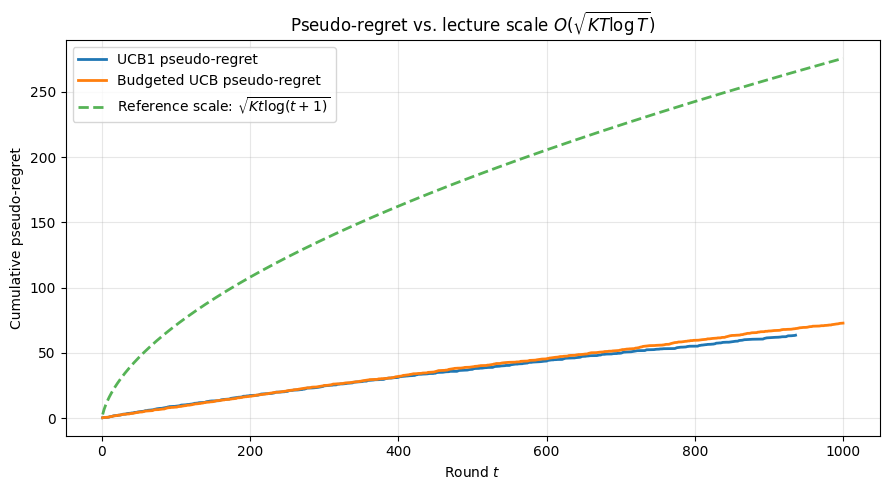

UCB1 ran for 936 rounds (stopped early: True)
Budgeted UCB ran for 1000 rounds (stopped early: False)
Final cumulative pseudo-regret (UCB1): 63.49
Final cumulative pseudo-regret (Budgeted UCB): 72.77
Lecture reference scale at T=1000: 275.6743


In [23]:
# ── Sublinear pseudo-regret verification: linear-scale lecture-aligned plot ────

fig, ax = plt.subplots(figsize=(9, 5))

K = len(bids)

def lecture_reference_scale(n_rounds):
    """
    Lecture-aligned UCB1 instance-independent scale:
        O(sqrt(K T log T))

    We plot sqrt(K t log(t+1)) only as a reference scale.
    No constant such as 8 is shown, because Big-O ignores constants.
    """
    t_range = np.arange(1, n_rounds + 1)
    reference = np.sqrt(K * t_range * np.log(t_range + 1))
    return t_range, reference


def add_pseudo_regret(df, value=1.0):
    """
    Compute cumulative pseudo-regret using expected rewards.

    In Req 1:
        m ~ Uniform(0,1)
        P(win | b) = b
        reward if win = value - b

    So:
        expected_reward(b) = (value - b) * b

    For value = 1:
        b* = 0.5
        expected_reward(b*) = 0.25
    """
    df = df.copy()

    optimal_bid = value / 2
    optimal_expected_reward = (value - optimal_bid) * optimal_bid

    df["expected_reward_action"] = (value - df["action"]) * df["action"]

    df["instant_pseudo_regret"] = (
        optimal_expected_reward - df["expected_reward_action"]
    )

    df["instant_pseudo_regret"] = df["instant_pseudo_regret"].clip(lower=0)
    df["cumulative_pseudo_regret"] = df["instant_pseudo_regret"].cumsum()

    return df


ucb1_df_plot = add_pseudo_regret(ucb1_df, value=value)
budgeted_ucb_df_plot = add_pseudo_regret(budgeted_ucb_df, value=value)

ucb1_t_range, ucb1_reference = lecture_reference_scale(len(ucb1_df_plot))
budgeted_t_range, budgeted_reference = lecture_reference_scale(len(budgeted_ucb_df_plot))

# Use the full horizon reference, because Budgeted UCB reaches T=1000.
full_t_range, full_reference = lecture_reference_scale(horizon)

ax.plot(
    ucb1_df_plot["round"],
    ucb1_df_plot["cumulative_pseudo_regret"],
    label="UCB1 pseudo-regret",
    linewidth=2,
)

ax.plot(
    budgeted_ucb_df_plot["round"],
    budgeted_ucb_df_plot["cumulative_pseudo_regret"],
    label="Budgeted UCB pseudo-regret",
    linewidth=2,
)

ax.plot(
    full_t_range,
    full_reference,
    "--",
    label=r"Reference scale: $\sqrt{Kt\log(t+1)}$",
    linewidth=2,
    alpha=0.8,
)

ax.set_xlabel("Round $t$")
ax.set_ylabel("Cumulative pseudo-regret")
ax.set_title(r"Pseudo-regret vs. lecture scale $O(\sqrt{KT\log T})$")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(plots_dir / "req1_pseudo_regret_linear_lecture_scale.png", dpi=200)
plt.show()

print(f"UCB1 ran for {len(ucb1_df_plot)} rounds (stopped early: {len(ucb1_df_plot) < horizon})")
print(f"Budgeted UCB ran for {len(budgeted_ucb_df_plot)} rounds (stopped early: {len(budgeted_ucb_df_plot) < horizon})")

print(
    "Final cumulative pseudo-regret (UCB1):",
    round(ucb1_df_plot["cumulative_pseudo_regret"].iloc[-1], 4),
)

print(
    "Final cumulative pseudo-regret (Budgeted UCB):",
    round(budgeted_ucb_df_plot["cumulative_pseudo_regret"].iloc[-1], 4),
)

print(
    "Lecture reference scale at T=1000:",
    round(full_reference[-1], 4),
)

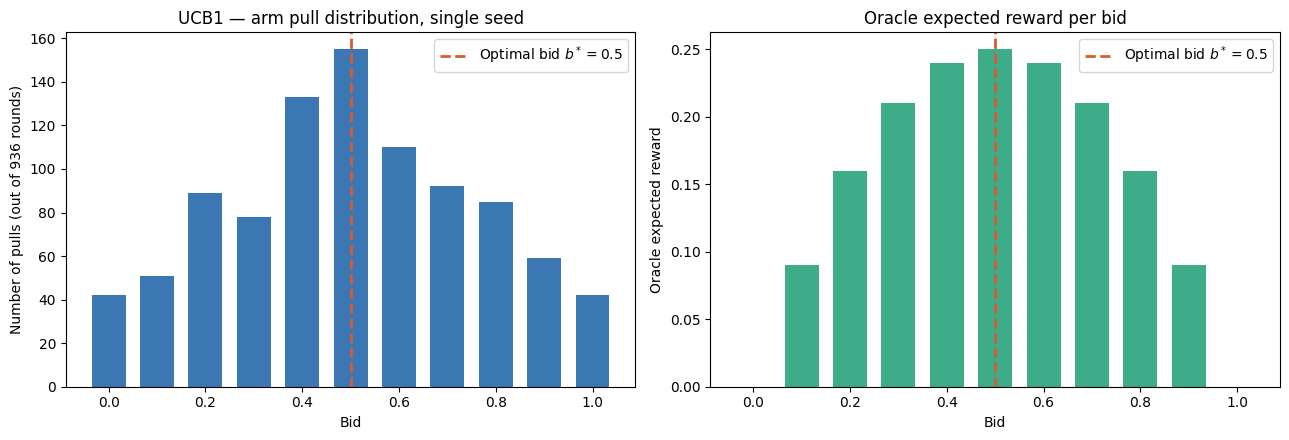

Most-pulled bid: 0.5
Share of played rounds spent on optimal bid (0.5): 0.166
Rounds played by UCB1 in this single seed: 936


In [24]:
# ── Arm pull distribution vs. oracle expected reward, single seed ────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pull_counts = ucb1_df["action"].value_counts().reindex(bids, fill_value=0)

axes[0].bar(bids, pull_counts.values, width=0.07, color="#185FA5", alpha=0.85)
axes[0].axvline(
    0.5,
    color="#D85A30",
    linestyle="--",
    linewidth=2,
    label="Optimal bid $b^*=0.5$",
)
axes[0].set_xlabel("Bid")
axes[0].set_ylabel(f"Number of pulls (out of {len(ucb1_df)} rounds)")
axes[0].set_title("UCB1 — arm pull distribution, single seed")
axes[0].legend()

oracle_reward = (value - bids) * bids

axes[1].bar(bids, oracle_reward, width=0.07, color="#1D9E75", alpha=0.85)
axes[1].axvline(
    0.5,
    color="#D85A30",
    linestyle="--",
    linewidth=2,
    label="Optimal bid $b^*=0.5$",
)
axes[1].set_xlabel("Bid")
axes[1].set_ylabel("Oracle expected reward")
axes[1].set_title("Oracle expected reward per bid")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "req1_arm_pull_distribution_single_seed.png", dpi=200)
plt.show()

print("Most-pulled bid:", pull_counts.idxmax())
print(
    "Share of played rounds spent on optimal bid (0.5):",
    round(pull_counts.loc[0.5] / pull_counts.sum(), 3),
)
print("Rounds played by UCB1 in this single seed:", len(ucb1_df))

 ## Optional appendix: Thompson Sampling diagnostic

This section is exploratory and is not part of the required Req 1 comparison.

In [25]:
# ── Thompson Sampling agent for first-price auction bidding ────────────────
class BiddingThompsonSampling:
    """Thompson Sampling adapted to single-campaign bidding.

    Each bid b has an unknown win probability p_b = P(b >= m).
    We place a Beta(1,1) prior on p_b and update it as a Bernoulli bandit
    (win/loss), then pick the bid maximizing sampled expected reward
    among bids that are affordable under the per-round budget rho.
    """

    def __init__(self, actions, value, horizon, initial_budget, random_seed=None):
        self.actions = np.asarray(actions, dtype=float)
        self.value = value
        self.horizon = horizon
        self.budget_left = initial_budget
        self.rho = initial_budget / horizon
        self.rng = np.random.default_rng(random_seed)

        n = len(self.actions)
        self.alpha = np.ones(n)
        self.beta = np.ones(n)
        self.counts = np.zeros(n, dtype=int)
        self._posterior_snapshots = {}

    def select_action(self):
        theta = self.rng.beta(self.alpha, self.beta)
        expected_reward = (self.value - self.actions) * theta
        expected_cost = self.actions * theta

        feasible = expected_cost <= self.rho
        if not feasible.any():
            feasible = np.ones_like(feasible, dtype=bool)

        masked_reward = np.where(feasible, expected_reward, -np.inf)
        idx = int(np.argmax(masked_reward))
        return self.actions[idx]

    def update(self, action, won, cost):
        idx = np.where(self.actions == action)[0][0]
        self.alpha[idx] += int(won)
        self.beta[idx] += int(not won)
        self.counts[idx] += 1
        self.budget_left -= cost

    def snapshot_posterior(self, round_idx):
        self._posterior_snapshots[round_idx] = (self.alpha.copy(), self.beta.copy())

In [26]:
# ── Run Thompson Sampling over the same horizon and seed ───────────────────
from scipy.stats import beta as beta_dist

ts_agent = BiddingThompsonSampling(
    actions=bids, value=value, horizon=horizon,
    initial_budget=initial_budget, random_seed=random_seed,
)
rng = np.random.default_rng(random_seed)
snapshot_rounds = {10, 50, 200, 1000}

ts_rows = []
budget_left = initial_budget

for t in range(1, horizon + 1):
    bid = ts_agent.select_action()
    m_t = rng.uniform(min_competing_bid, max_competing_bid)
    won = int(bid >= m_t)
    reward = (value - bid) if won else 0.0
    cost = bid if won else 0.0
    effective_cost = min(cost, budget_left)

    ts_agent.update(action=bid, won=bool(won), cost=effective_cost)
    budget_left -= effective_cost

    if t in snapshot_rounds:
        ts_agent.snapshot_posterior(t)

    ts_rows.append({
        "round": t, "action": bid, "wins": won,
        "reward": reward, "cost": effective_cost, "budget_left": budget_left,
    })

ts_df = pd.DataFrame(ts_rows)
ts_df["cumulative_reward"] = ts_df["reward"].cumsum()
ts_df["cumulative_cost"] = ts_df["cost"].cumsum()
ts_df["cumulative_regret"] = budgeted_ucb_benchmark * ts_df["round"] - ts_df["cumulative_reward"]

print("Thompson Sampling — total reward:", ts_df["cumulative_reward"].iloc[-1])
print("Thompson Sampling — final regret:", ts_df["cumulative_regret"].iloc[-1])
print("Thompson Sampling — final budget left:", ts_df["budget_left"].iloc[-1])

Thompson Sampling — total reward: 224.79999999999987
Thompson Sampling — final regret: 25.20000000000013
Thompson Sampling — final budget left: 123.80000000000116


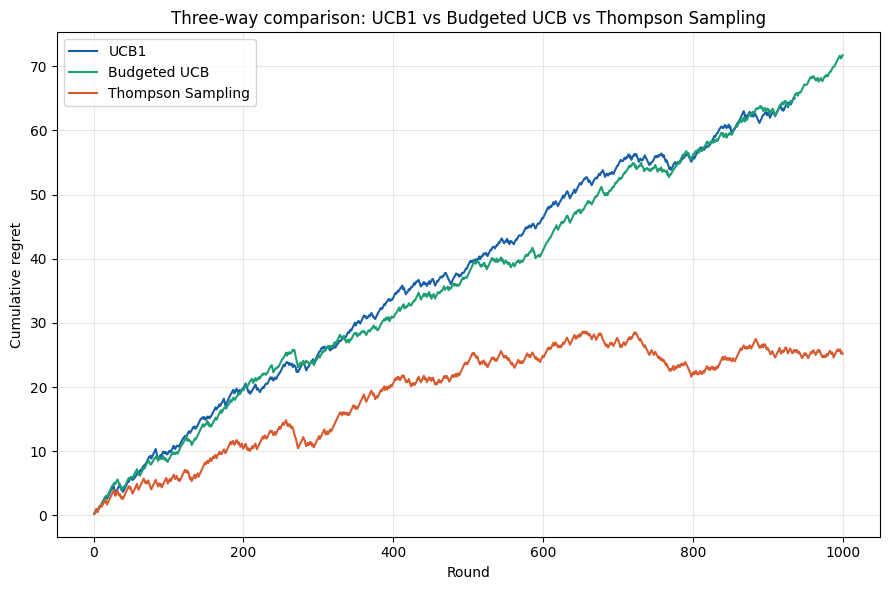

In [27]:
# ── Three-way comparison: UCB1 vs Budgeted UCB vs Thompson Sampling ────────
fig, ax = plt.subplots(figsize=(9, 6))
for df, name, color in [
    (ucb1_df, "UCB1", "#185FA5"),
    (budgeted_ucb_df, "Budgeted UCB", "#1D9E75"),
    (ts_df, "Thompson Sampling", "#D85A30"),
]:
    ax.plot(df["round"], df["cumulative_regret"], label=name, color=color)

ax.set_xlabel("Round")
ax.set_ylabel("Cumulative regret")
ax.set_title("Three-way comparison: UCB1 vs Budgeted UCB vs Thompson Sampling")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(plots_dir / "req1_three_way_regret_comparison.png", dpi=200)
plt.show()

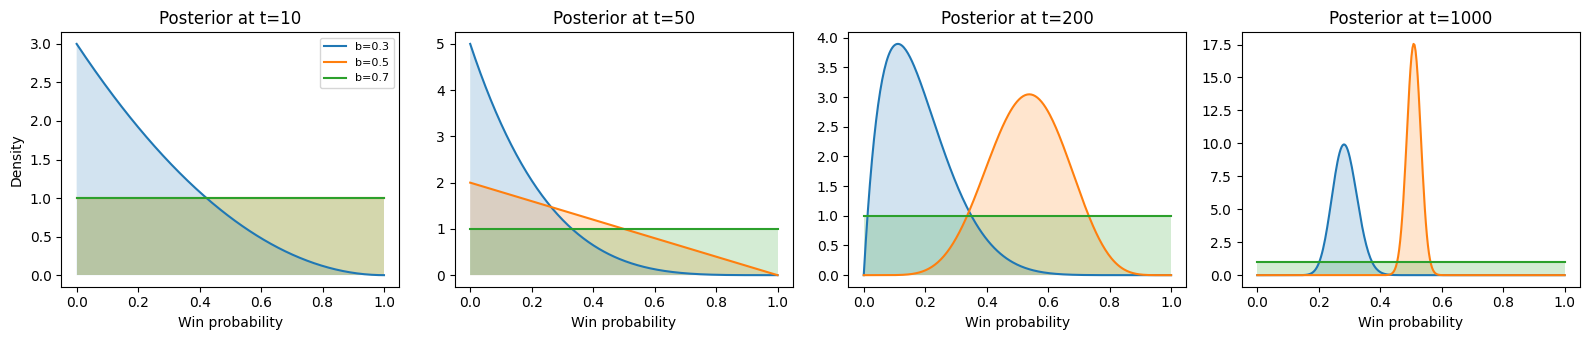

In [28]:
# ── Posterior evolution: how Thompson Sampling's beliefs sharpen over time ─
def plot_beta_pdf(alpha, beta_param, ax, label=None):
    x = np.linspace(0, 1, 300)
    y = beta_dist.pdf(x, alpha, beta_param)
    ax.plot(x, y, label=label)
    ax.fill_between(x, y, alpha=0.2)

bids_to_track = [0.3, 0.5, 0.7]
bid_indices = [np.where(bids == b)[0][0] for b in bids_to_track]
snapshot_rounds_sorted = sorted(ts_agent._posterior_snapshots.keys())

fig, axes = plt.subplots(1, len(snapshot_rounds_sorted), figsize=(16, 3.5))
for col, t in enumerate(snapshot_rounds_sorted):
    alpha_t, beta_t = ts_agent._posterior_snapshots[t]
    for b, idx in zip(bids_to_track, bid_indices):
        plot_beta_pdf(alpha_t[idx], beta_t[idx], axes[col], label=f"b={b}")
    axes[col].set_title(f"Posterior at t={t}")
    axes[col].set_xlabel("Win probability")
    if col == 0:
        axes[col].set_ylabel("Density")
        axes[col].legend(fontsize=8)

plt.tight_layout()
plt.savefig(plots_dir / "req1_ts_posterior_evolution.png", dpi=200)
plt.show()

**Why Thompson Sampling here.** The win event at bid $b$ is Bernoulli with parameter
$p_b = P(b \geq m)$, so a Beta(1,1) prior is conjugate and exact. the posterior over the win probability for b=0.5 visibly sharpens, converging toward its true win probability, consistent with b=0.5 being the analytically optimal bid. This gives a direct
visual account of exploration-exploitation that the regret curve alone doesn't show.

In [29]:
MULTI_SEED_VALUES = list(range(30))


def run_req1_for_seed(seed, budget, label):
    """Run both Req 1 algorithms for one seed and one budget setting."""
    ucb1_benchmark_seed, budgeted_ucb_benchmark_seed = compute_req1_benchmarks(
        bids=bids,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
    )

    ucb1_seed = UCB1(actions=bids, horizon=horizon)
    ucb1_seed_rows = run_algorithm(
        algorithm_name="ucb1",
        learner=ucb1_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=ucb1_benchmark_seed,
    )

    budgeted_ucb_seed = BudgetedUCB(
        actions=bids,
        horizon=horizon,
        initial_budget=budget,
    )
    budgeted_ucb_seed_rows = run_algorithm(
        algorithm_name="budgeted_ucb",
        learner=budgeted_ucb_seed,
        value=value,
        initial_budget=budget,
        horizon=horizon,
        random_seed=seed,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        benchmark_reward_per_round=budgeted_ucb_benchmark_seed,
    )

    seed_df = pd.DataFrame(ucb1_seed_rows + budgeted_ucb_seed_rows)
    seed_df["seed"] = seed
    seed_df["budget_setting"] = label
    seed_df["initial_budget"] = budget

    return seed_df


multi_seed_frames = []

for seed in MULTI_SEED_VALUES:
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=initial_budget,
            label="official_budget_B_300",
        )
    )
    multi_seed_frames.append(
        run_req1_for_seed(
            seed=seed,
            budget=150.0,
            label="tight_budget_B_150",
        )
    )

multi_seed_results = pd.concat(multi_seed_frames, ignore_index=True)

print("Multi-seed result shape:", multi_seed_results.shape)
print("Number of seeds:", multi_seed_results["seed"].nunique())
print("Budget settings:")
print(multi_seed_results["budget_setting"].value_counts())
print("\nAlgorithms:")
print(multi_seed_results["algorithm"].value_counts())

Multi-seed result shape: (103203, 19)
Number of seeds: 30
Budget settings:
budget_setting
official_budget_B_300    58659
tight_budget_B_150       44544
Name: count, dtype: int64

Algorithms:
algorithm
budgeted_ucb    60000
ucb1            43203
Name: count, dtype: int64


In [30]:
multi_seed_summary = (
    multi_seed_results
    .sort_values(["budget_setting", "seed", "algorithm", "round"])
    .groupby(["budget_setting", "initial_budget", "seed", "algorithm"])
    .agg(
        rounds_played=("round", "max"),
        total_reward=("cumulative_reward", "last"),
        total_cost=("cumulative_cost", "last"),
        final_budget_left=("budget_left", "last"),
        final_cumulative_regret=("cumulative_regret", "last"),
    )
    .reset_index()
)

multi_seed_aggregate_summary = (
    multi_seed_summary
    .groupby(["budget_setting", "initial_budget", "algorithm"])
    .agg(
        mean_rounds_played=("rounds_played", "mean"),
        std_rounds_played=("rounds_played", "std"),
        mean_total_reward=("total_reward", "mean"),
        std_total_reward=("total_reward", "std"),
        mean_total_cost=("total_cost", "mean"),
        std_total_cost=("total_cost", "std"),
        mean_final_budget_left=("final_budget_left", "mean"),
        std_final_budget_left=("final_budget_left", "std"),
        early_stop_rate=("rounds_played", lambda values: float((values < horizon).mean())),
    )
    .reset_index()
)

multi_seed_aggregate_summary

,budget_setting,initial_budget,algorithm,mean_rounds_played,std_rounds_played,mean_total_reward,std_total_reward,mean_total_cost,std_total_cost,mean_final_budget_left,std_final_budget_left,early_stop_rate
0,official_budget_B_300,300.0,budgeted_ucb,1000.0,0.000000,184.833333,8.721884,299.766667,3.651484e-01,2.333333e-01,3.651484e-01,0.000000
1,official_budget_B_300,300.0,ucb1,955.3,27.224672,171.343333,8.083345,299.856667,5.379933e-01,1.433333e-01,5.379933e-01,0.866667
2,tight_budget_B_150,150.0,budgeted_ucb,1000.0,0.000000,171.290000,7.077909,149.876667,1.278019e-01,1.233333e-01,1.278019e-01,0.000000
3,tight_budget_B_150,150.0,ucb1,484.8,100.004965,79.366667,5.149378,150.000000,8.640097e-14,1.017704e-15,5.574197e-15,0.966667


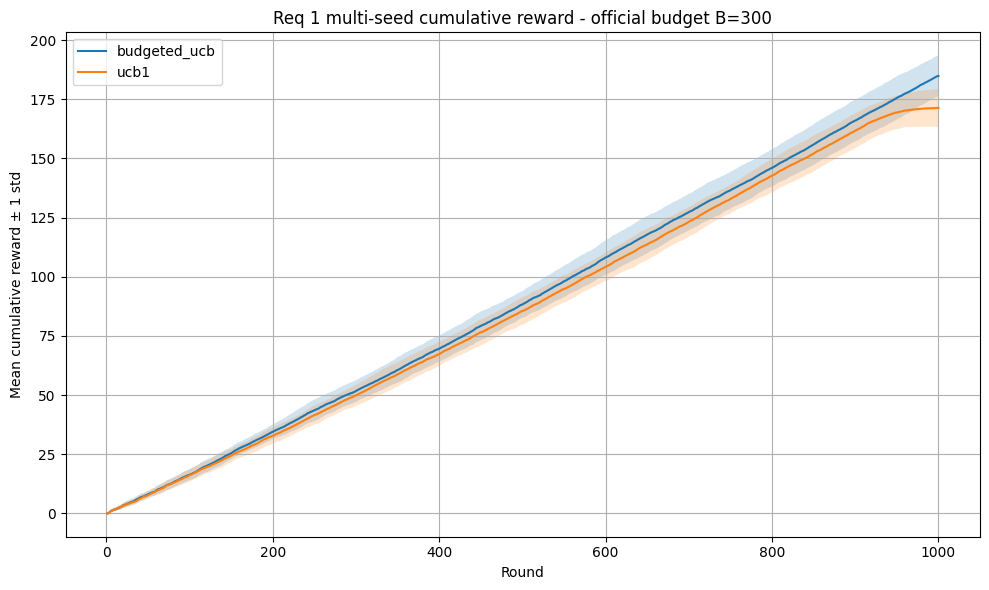

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_official_budget.png
Plot exists: True


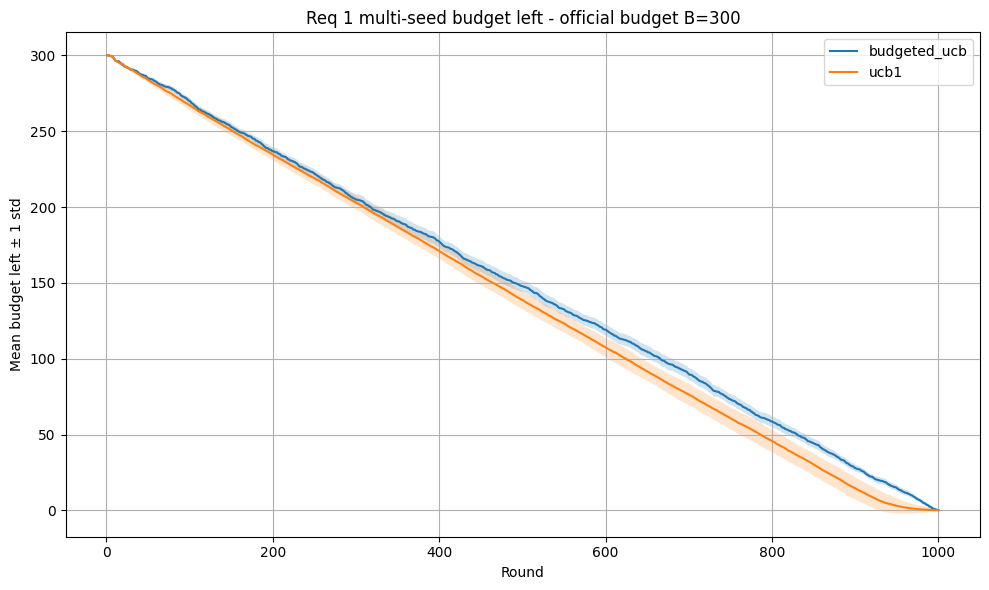

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_official_budget.png
Plot exists: True


In [31]:
def plot_mean_with_std_band(dataframe, budget_setting, metric, ylabel, title, output_filename):
    """Plot mean trajectory with plus/minus one standard deviation over seeds."""
    setting_df = dataframe[dataframe["budget_setting"] == budget_setting]

    plt.figure(figsize=(10, 6))

    for algorithm_name, group in setting_df.groupby("algorithm"):
        pivot = group.pivot_table(
            index="round",
            columns="seed",
            values=metric,
            aggfunc="last",
        ).sort_index()

        # Forward-fill so seeds that stopped early hold their last value
        # instead of disappearing from the mean for the remaining rounds.
        pivot = pivot.reindex(range(1, horizon + 1)).ffill()

        mean_values = pivot.mean(axis=1)
        std_values = pivot.std(axis=1).fillna(0.0)

        rounds = mean_values.index.to_numpy(dtype=float)
        mean_array = mean_values.to_numpy(dtype=float)
        std_array = std_values.to_numpy(dtype=float)

        plt.plot(rounds, mean_array, label=algorithm_name)
        plt.fill_between(
            rounds,
            mean_array - std_array,
            mean_array + std_array,
            alpha=0.2,
        )

    plt.xlabel("Round")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    output_path = plots_dir / output_filename
    plt.savefig(output_path, dpi=200)
    plt.show()

    print("Saved plot to:", output_path)
    print("Plot exists:", output_path.exists())


plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - official budget B=300",
    output_filename="req1_multiseed_reward_official_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="official_budget_B_300",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - official budget B=300",
    output_filename="req1_multiseed_budget_left_official_budget.png",
)

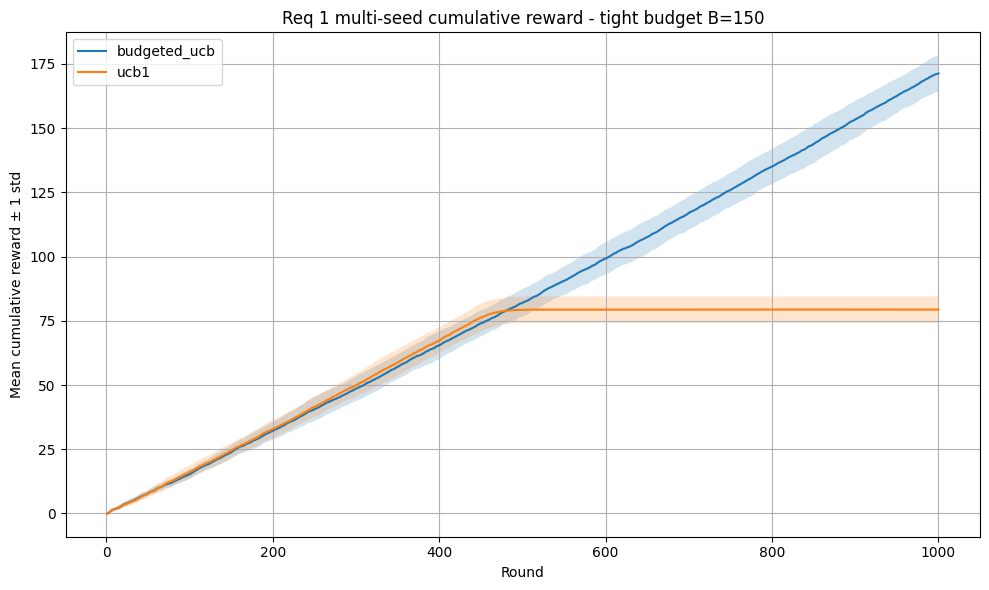

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_reward_tight_budget.png
Plot exists: True


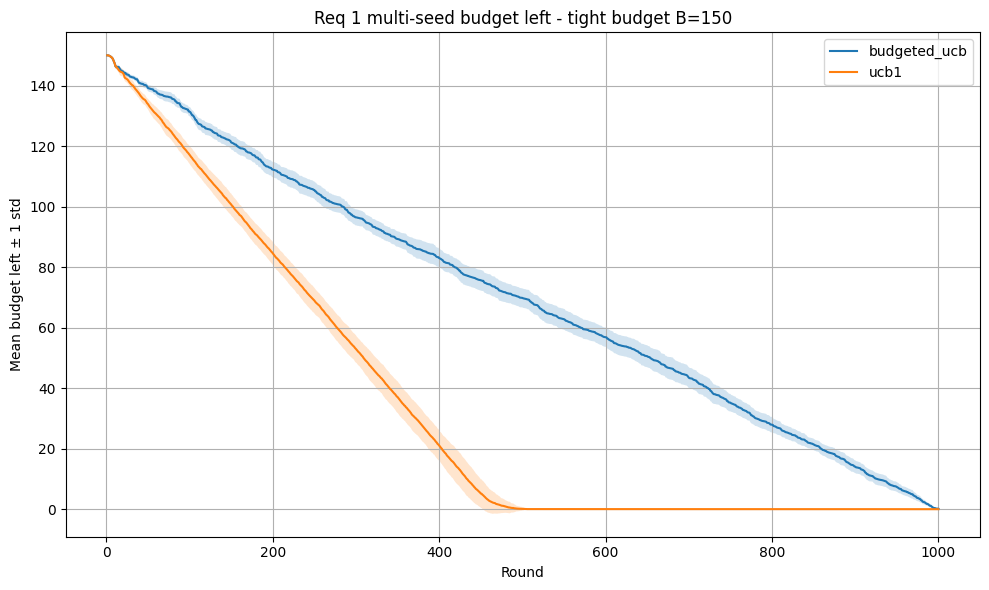

Saved plot to: /Users/foadzahedilabaf/Projects/ola-project/results/plots/req1_multiseed_budget_left_tight_budget.png
Plot exists: True


In [32]:
plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="cumulative_reward",
    ylabel="Mean cumulative reward ± 1 std",
    title="Req 1 multi-seed cumulative reward - tight budget B=150",
    output_filename="req1_multiseed_reward_tight_budget.png",
)

plot_mean_with_std_band(
    dataframe=multi_seed_results,
    budget_setting="tight_budget_B_150",
    metric="budget_left",
    ylabel="Mean budget left ± 1 std",
    title="Req 1 multi-seed budget left - tight budget B=150",
    output_filename="req1_multiseed_budget_left_tight_budget.png",
)

In [47]:
#Regret 
def expected_reward(b, value=1.0):
    return (value - b) * b


def expected_cost(b):
    return b ** 2


def solve_lp_benchmark(bids, value, horizon, initial_budget, tol=1e-12):
    bids_arr = np.array(bids, dtype=float)
    rewards = np.array([expected_reward(b, value) for b in bids_arr])
    costs = np.array([expected_cost(b) for b in bids_arr])

    rho = initial_budget / horizon
    n = len(bids_arr)

    best_dist = np.zeros(n)
    best_value = -np.inf

    def update_best(dist):
        nonlocal best_dist, best_value
        obj = float(np.dot(dist, rewards))
        if obj > best_value + tol:
            best_value = obj
            best_dist = dist.copy()

    for i in range(n):
        if costs[i] <= rho + tol:
            dist = np.zeros(n)
            dist[i] = 1.0
            update_best(dist)

    for i in range(n):
        for j in range(i + 1, n):
            ci, cj = costs[i], costs[j]

            if abs(ci - cj) <= tol:
                continue

            p_i = (rho - cj) / (ci - cj)
            p_j = 1.0 - p_i

            if -tol <= p_i <= 1.0 + tol and -tol <= p_j <= 1.0 + tol:
                dist = np.zeros(n)
                dist[i] = np.clip(p_i, 0.0, 1.0)
                dist[j] = np.clip(p_j, 0.0, 1.0)
                update_best(dist)

    if best_value == -np.inf:
        raise ValueError("No feasible benchmark found.")

    return {
        "rho": rho,
        "bids": bids_arr,
        "rewards": rewards,
        "costs": costs,
        "dist": best_dist,
        "opt": float(best_value),
        "opt_cost": float(np.dot(best_dist, costs)),
    }


def lp_pseudo_regret(
    data,
    bids,
    value,
    horizon,
    initial_budget,
    bid_column="effective_bid",
):
    bench = solve_lp_benchmark(
        bids=bids,
        value=value,
        horizon=horizon,
        initial_budget=initial_budget,
    )

    opt = bench["opt"]
    frames = []

    for algo in sorted(data["algorithm"].unique()):
        algo_data = data[data["algorithm"] == algo].copy()

        seeds = sorted(algo_data["seed"].unique()) if "seed" in algo_data.columns else [None]

        for seed in seeds:
            if seed is None:
                df = algo_data.copy()
            else:
                df = algo_data[algo_data["seed"] == seed].copy()

            df = df.sort_values("round").copy()

            if df.empty:
                continue

            used_col = bid_column if bid_column in df.columns else "action"
            played_bids = df[used_col].astype(float).to_numpy()
            played_rewards = np.array([expected_reward(b, value) for b in played_bids])

            df["lp_expected_reward"] = played_rewards
            df["lp_cumulative_expected_reward"] = df["lp_expected_reward"].cumsum()

            full = pd.DataFrame({"round": np.arange(1, horizon + 1)})

            full = full.merge(
                df[["round", "lp_cumulative_expected_reward"]],
                on="round",
                how="left",
            )

            full["lp_cumulative_expected_reward"] = (
                full["lp_cumulative_expected_reward"]
                .ffill()
                .fillna(0.0)
            )

            full["lp_cumulative_pseudo_regret"] = (
                full["round"] * opt - full["lp_cumulative_expected_reward"]
            )

            full["lp_average_pseudo_regret"] = (
                full["lp_cumulative_pseudo_regret"] / full["round"]
            )

            full["algorithm"] = algo

            if seed is not None:
                full["seed"] = seed

            frames.append(full)

    regret_df = pd.concat(frames, ignore_index=True)

    return regret_df, bench


def show_lp_benchmark(bench):
    out = pd.DataFrame({
        "bid": bench["bids"],
        "probability": bench["dist"],
        "expected_reward": bench["rewards"],
        "expected_cost": bench["costs"],
    })

    print("rho:", round(bench["rho"], 6))
    print("benchmark reward:", round(bench["opt"], 6))
    print("benchmark cost:", round(bench["opt_cost"], 6))

    display(out[out["probability"] > 1e-10])

    return out

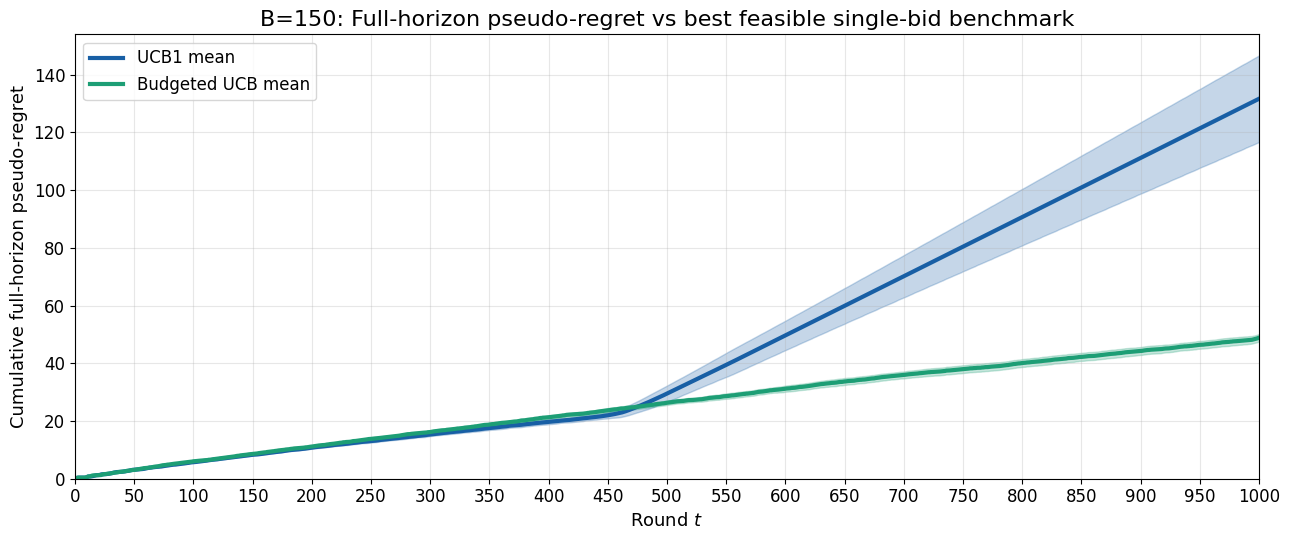

Using B=150 budget setting: tight_budget_B_150
rho: 0.15
Feasible bids: [0.0, 0.1, 0.2, 0.3]
Benchmark bid: 0.3
Benchmark expected reward: 0.21
Benchmark expected cost: 0.09
Number of seeds: 30
Final mean full-horizon pseudo-regret B=150 (UCB1): 131.66
Final mean full-horizon pseudo-regret B=150 (Budgeted UCB): 48.85


In [ ]:
# Tight budget B=150 LP-benchmark pseudo-regret over 30 seeds

budget_filter = "tight_budget_B_150"

tight_data = multi_seed_results[
    multi_seed_results["budget_setting"] == budget_filter
].copy()

lp_regret_B150_df, lp_bench_B150 = lp_pseudo_regret(
    data=tight_data,
    bids=bids,
    value=value,
    horizon=horizon,
    initial_budget=150,
    bid_column="effective_bid",
)

show_lp_benchmark(lp_bench_B150)

fig, ax = plt.subplots(figsize=(13, 5.5))

final_mean_pseudo_regret_B150 = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = lp_regret_B150_df[
        lp_regret_B150_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="lp_cumulative_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_mean_pseudo_regret_B150[algo] = mean_regret[-1]

    ax.plot(rounds, mean_regret, label=f"{label} mean", color=color, lw=3)
    ax.fill_between(
        rounds,
        mean_regret - std_regret,
        mean_regret + std_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(0, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Cumulative pseudo-regret $R_t$", fontsize=13)
ax.set_title("B=150: LP-benchmark full-horizon pseudo-regret", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_lp_pseudo_regret_B150.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Using budget setting:", budget_filter)
print("Final mean LP pseudo-regret B=150 (UCB1):", round(final_mean_pseudo_regret_B150["ucb1"], 2))
print("Final mean LP pseudo-regret B=150 (Budgeted UCB):", round(final_mean_pseudo_regret_B150["budgeted_ucb"], 2))

rho: 0.3
benchmark reward: 0.25
benchmark cost: 0.25


,bid,probability,expected_reward,expected_cost
5,0.5,1.0,0.25,0.25


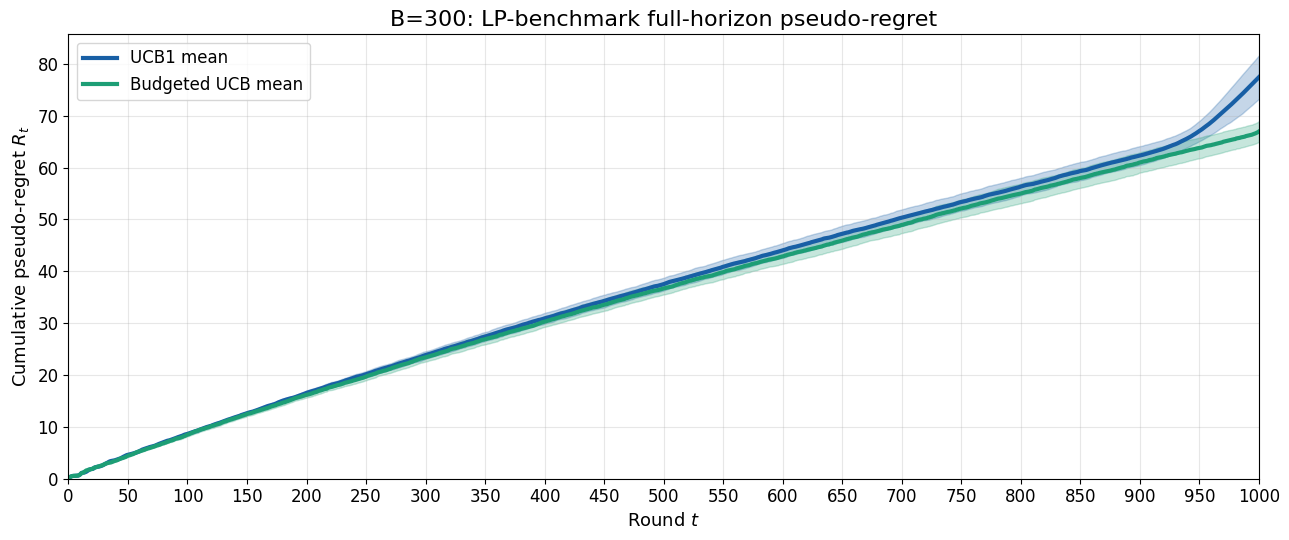

Using budget setting: official_budget_B_300
Final mean LP pseudo-regret B=300 (UCB1): 77.45
Final mean LP pseudo-regret B=300 (Budgeted UCB): 66.98


In [50]:
# Official B=300 LP-benchmark pseudo-regret over 30 seeds

budget_filter = "official_budget_B_300"

official_data = multi_seed_results[
    multi_seed_results["budget_setting"] == budget_filter
].copy()

lp_regret_B300_df, lp_bench_B300 = lp_pseudo_regret(
    data=official_data,
    bids=bids,
    value=value,
    horizon=horizon,
    initial_budget=300,
    bid_column="effective_bid",
)

show_lp_benchmark(lp_bench_B300)

pseudo_regret_df = lp_regret_B300_df.copy()

fig, ax = plt.subplots(figsize=(13, 5.5))

final_mean_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = lp_regret_B300_df[
        lp_regret_B300_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="lp_cumulative_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_mean_pseudo_regret[algo] = mean_regret[-1]

    ax.plot(rounds, mean_regret, label=f"{label} mean", color=color, lw=3)
    ax.fill_between(
        rounds,
        mean_regret - std_regret,
        mean_regret + std_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(0, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Cumulative pseudo-regret $R_t$", fontsize=13)
ax.set_title("B=300: LP-benchmark full-horizon pseudo-regret", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_lp_pseudo_regret_B300.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Using budget setting:", budget_filter)
print("Final mean LP pseudo-regret B=300 (UCB1):", round(final_mean_pseudo_regret["ucb1"], 2))
print("Final mean LP pseudo-regret B=300 (Budgeted UCB):", round(final_mean_pseudo_regret["budgeted_ucb"], 2))

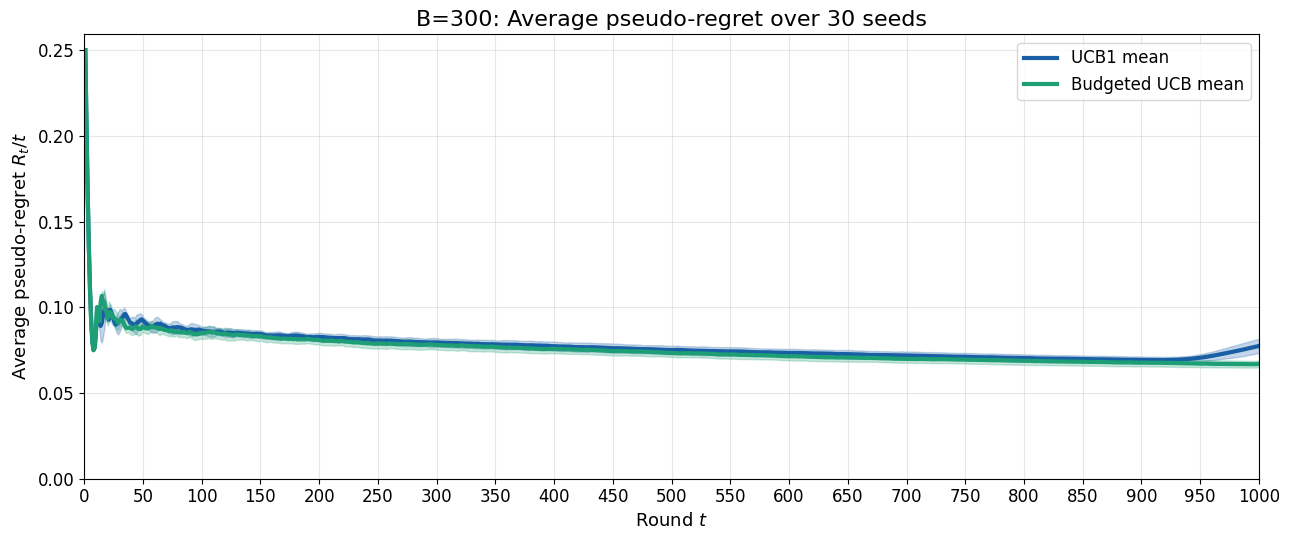

Final average pseudo-regret B=300 (UCB1): 0.0775
Final average pseudo-regret B=300 (Budgeted UCB): 0.067


In [52]:
# Average pseudo-regret R_t / t for official B=300
# This plot is useful because sublinear regret means R_t / t decreases toward zero.

if "pseudo_regret_df" not in globals():
    raise NameError("Run the B=300 full-horizon pseudo-regret cell first.")

average_regret_df = lp_regret_B300_df.copy()
average_regret_df["average_pseudo_regret"] = average_regret_df["lp_average_pseudo_regret"]


fig, ax = plt.subplots(figsize=(13, 5.5))

final_average_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = average_regret_df[
        average_regret_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="average_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_average_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_average_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_average_pseudo_regret[algo] = mean_average_regret[-1]

    ax.plot(
        rounds,
        mean_average_regret,
        label=f"{label} mean",
        color=color,
        lw=3,
    )

    ax.fill_between(
        rounds,
        mean_average_regret - std_average_regret,
        mean_average_regret + std_average_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(1, horizon)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, horizon + 1, 50))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Average pseudo-regret $R_t / t$", fontsize=13)
ax.set_title("B=300: Average pseudo-regret over 30 seeds", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_average_pseudo_regret_B300.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Final average pseudo-regret B=300 (UCB1):", round(final_average_pseudo_regret["ucb1"], 4))
print("Final average pseudo-regret B=300 (Budgeted UCB):", round(final_average_pseudo_regret["budgeted_ucb"], 4))

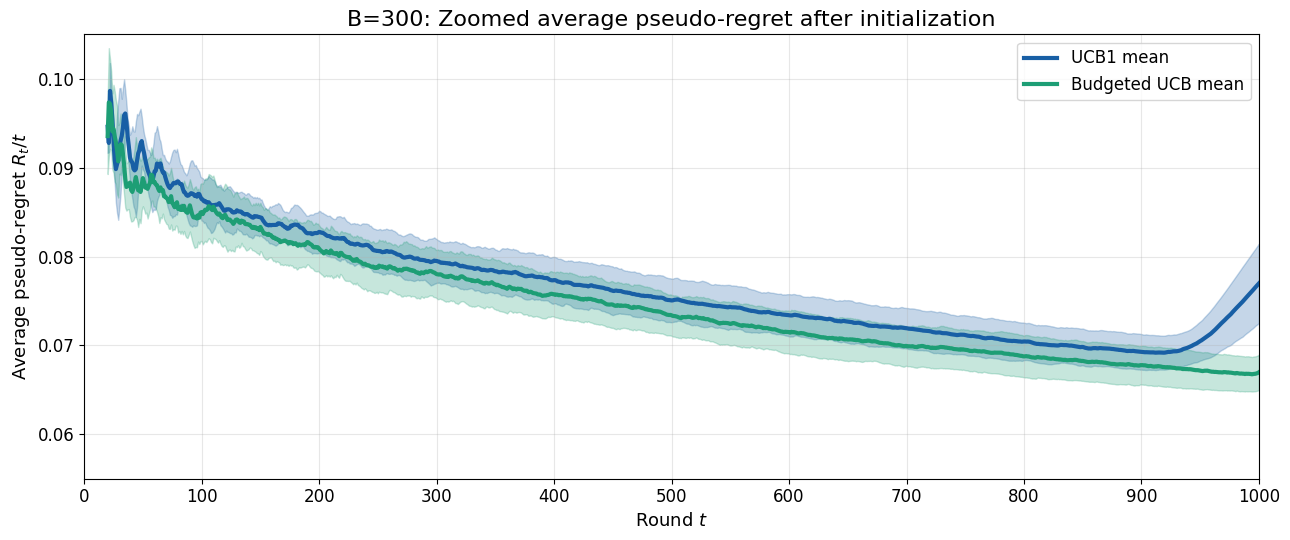

Final zoomed average pseudo-regret B=300 (UCB1): 0.077
Final zoomed average pseudo-regret B=300 (Budgeted UCB): 0.067


In [38]:
# Zoomed average pseudo-regret plot for readability
# We remove the first 20 rounds only from the visualization because early initialization dominates the scale.
# The data and regret computation are unchanged.

if "average_regret_df" not in globals():
    raise NameError("Run the average pseudo-regret cell first.")

zoom_start_round = 20

zoom_df = average_regret_df[
    average_regret_df["round"] >= zoom_start_round
].copy()

fig, ax = plt.subplots(figsize=(13, 5.5))

final_zoom_average_pseudo_regret = {}

for algo in ["ucb1", "budgeted_ucb"]:
    color = "#185FA5" if algo == "ucb1" else "#1D9E75"
    label = "UCB1" if algo == "ucb1" else "Budgeted UCB"

    pivot = zoom_df[
        zoom_df["algorithm"] == algo
    ].pivot_table(
        index="round",
        columns="seed",
        values="average_pseudo_regret",
        aggfunc="last",
    ).sort_index()

    mean_average_regret = pivot.mean(axis=1).to_numpy(dtype=float)
    std_average_regret = pivot.std(axis=1).fillna(0).to_numpy(dtype=float)
    rounds = pivot.index.to_numpy(dtype=float)

    final_zoom_average_pseudo_regret[algo] = mean_average_regret[-1]

    ax.plot(
        rounds,
        mean_average_regret,
        label=f"{label} mean",
        color=color,
        lw=3,
    )

    ax.fill_between(
        rounds,
        mean_average_regret - std_average_regret,
        mean_average_regret + std_average_regret,
        color=color,
        alpha=0.25,
    )

ax.set_xlim(zoom_start_round, horizon)
ax.set_ylim(0.055, 0.105)
ax.set_xticks(np.arange(0, horizon + 1, 100))
ax.set_xlabel("Round $t$", fontsize=13)
ax.set_ylabel("Average pseudo-regret $R_t/t$", fontsize=13)
ax.set_title(
    "B=300: Zoomed average pseudo-regret after initialization",
    fontsize=16,
)
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig(
    plots_dir / "req1_average_pseudo_regret_B300_zoomed.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    "Final zoomed average pseudo-regret B=300 (UCB1):",
    round(final_zoom_average_pseudo_regret["ucb1"], 4),
)

print(
    "Final zoomed average pseudo-regret B=300 (Budgeted UCB):",
    round(final_zoom_average_pseudo_regret["budgeted_ucb"], 4),
)

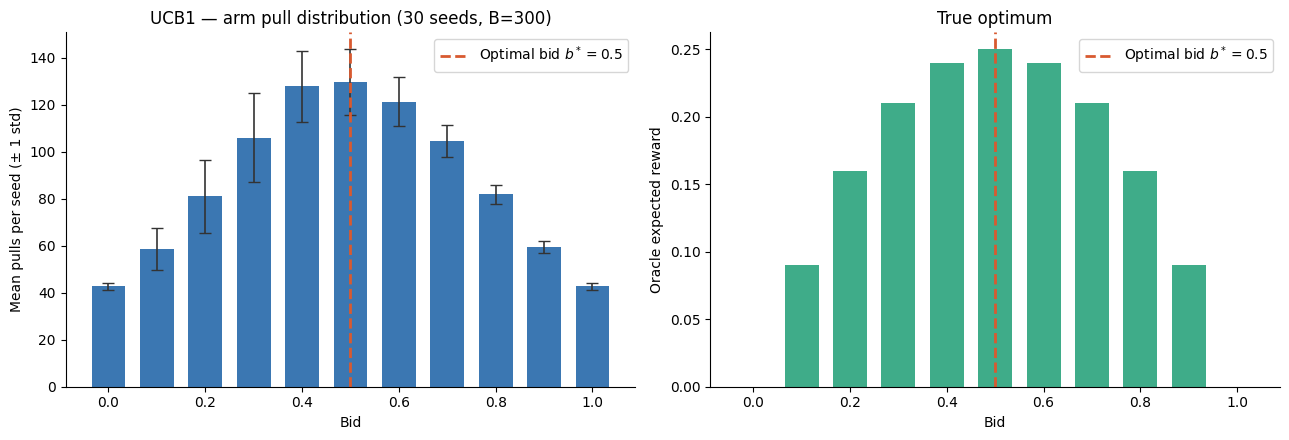

Most-pulled bid on average: 0.5
Mean share of rounds on bid 0.5: 0.136


In [35]:
# ── Arm pull distribution averaged across 30 seeds ─────────────────────────
import matplotlib.pyplot as plt
import numpy as np

# Filter only UCB1 rows from the multi-seed results
ucb1_multi = multi_seed_results[
    (multi_seed_results["algorithm"] == "ucb1") &
    (multi_seed_results["budget_setting"] == "official_budget_B_300")
]

# Count pulls per bid per seed, then average across seeds
pull_counts_per_seed = (
    ucb1_multi.groupby(["seed", "action"])
    .size()
    .reset_index(name="pulls")
)

mean_pulls = (
    pull_counts_per_seed.groupby("action")["pulls"]
    .agg(["mean", "std"])
    .reindex(bids, fill_value=0)
    .fillna(0)
)

oracle_reward = (value - bids) * bids

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: mean pulls per bid with error bars
axes[0].bar(bids, mean_pulls["mean"], width=0.07,
            color="#185FA5", alpha=0.85,
            yerr=mean_pulls["std"], capsize=4,
            error_kw={"linewidth": 1.2, "ecolor": "#333"})
axes[0].axvline(0.5, color="#D85A30", linestyle="--",
                linewidth=2, label="Optimal bid $b^*=0.5$")
axes[0].set_xlabel("Bid")
axes[0].set_ylabel("Mean pulls per seed (± 1 std)")
axes[0].set_title("UCB1 — arm pull distribution (30 seeds, B=300)")
axes[0].legend()
axes[0].spines[["top", "right"]].set_visible(False)

# Right: oracle expected reward (same as before)
axes[1].bar(bids, oracle_reward, width=0.07,
            color="#1D9E75", alpha=0.85)
axes[1].axvline(0.5, color="#D85A30", linestyle="--",
                linewidth=2, label="Optimal bid $b^*=0.5$")
axes[1].set_xlabel("Bid")
axes[1].set_ylabel("Oracle expected reward")
axes[1].set_title("True optimum")
axes[1].legend()
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(plots_dir / "req1_arm_pull_distribution_multiseed.png", dpi=200)
plt.show()

# Print summary
most_pulled = mean_pulls["mean"].idxmax()
share = mean_pulls.loc[0.5, "mean"] / mean_pulls["mean"].sum()
print(f"Most-pulled bid on average: {most_pulled}")
print(f"Mean share of rounds on bid 0.5: {round(share, 3)}")

**Interpretation.** Across 30 seeds, UCB1 pulls bid \(b=0.5\) most often on average. This matches the analytical optimum.

The average share of pulls on \(b=0.5\) is 13.6%, which is above the uniform baseline:

$$
1/11 \approx 9.1\%.
$$

The distribution is still spread around nearby bids such as 0.4 and 0.6. This is expected because their oracle rewards are very close to the optimum. For example:

$$
\mu(0.5)=0.25,
\qquad
\mu(0.4)=0.24.
$$

So the absolute gap is only 0.01.

In [36]:
extra_plot_files = [
    "req1_multiseed_reward_official_budget.png",
    "req1_multiseed_budget_left_official_budget.png",
    "req1_multiseed_reward_tight_budget.png",
    "req1_multiseed_budget_left_tight_budget.png",
]

for filename in extra_plot_files:
    plot_path = plots_dir / filename
    print(filename, "exists:", plot_path.exists())

req1_multiseed_reward_official_budget.png exists: True
req1_multiseed_budget_left_official_budget.png exists: True
req1_multiseed_reward_tight_budget.png exists: True
req1_multiseed_budget_left_tight_budget.png exists: True


## Robustness experiment interpretation

The multi-seed experiment repeats the comparison over 30 independent stochastic
environments. The solid lines show the average behavior, while the shaded regions
represent plus/minus one standard deviation across seeds.

Under the official budget $B=300$, Budgeted UCB achieves higher average total reward:

$$
184.8 \pm 8.7
$$

compared with UCB1:

$$
171.3 \pm 8.1.
$$

This is consistent with Budgeted UCB's budget-pacing advantage. UCB1 stops early in
86.7% of seeds, while Budgeted UCB reaches the full horizon in all 30 seeds.

The tighter-budget stress test makes the budget constraint more binding. With $B=150$,
the per-round budget becomes:

$$
\rho = 150/1000 = 0.15.
$$

In this case, the reward-maximizing bid $b=0.5$ is no longer feasible in expectation,
because its expected cost is:

$$
\mathbb{E}[\text{cost at } b=0.5] = 0.5 \cdot 0.5 = 0.25 > 0.15.
$$

Under this tighter budget, the difference becomes much larger. UCB1 obtains:

$$
79.4 \pm 5.1
$$

while Budgeted UCB obtains:

$$
171.3 \pm 7.1.
$$

UCB1 stops after about 484.8 rounds on average, while Budgeted UCB keeps the interaction
feasible until the final round in every seed.

These additional experiments do not replace the official Requirement 1 configuration.
They strengthen the empirical analysis by showing average behavior, variability across
seeds, and performance under a more restrictive budget.

## Requirement 1 completion checklist

Requirement 1 is complete for the current project configuration.

What this notebook verifies:

- The environment is a single-campaign stochastic first-price auction environment.
- The competing bid is sampled from a fixed uniform distribution.
- Rewards and costs follow the first-price auction rule using the executed bid. If the bid wins, reward is `value - effective_bid` and cost is `effective_bid`; otherwise both are zero.
- The logged `action` and `bids` columns store the selected bid, as required by the shared output format.
- The extra `effective_bid` column stores the executed bid after budget clipping.
- When the selected bid is larger than the remaining budget, the environment clips the effective bid to avoid negative budget. This is a practical implementation choice and is documented in the notebook.
- UCB1 learns over the finite bid set while ignoring the budget constraint.
- Budgeted UCB learns both rewards and costs and uses a budget-aware LP rule to control spending.
- The shared CSV output format is respected.
- The generated plots compare reward, budget usage, cumulative cost, selected bids, and pseudo-regret.
- The robustness experiment repeats the comparison over 30 independent seeds.
- The robustness experiment reports mean and standard deviation across seeds.
- The tighter-budget stress test shows how the algorithms behave when the budget constraint is more binding.

Main empirical conclusion:

- In the official single-seed configuration, Budgeted UCB reaches the full horizon while UCB1 stops early around round 936 once its budget is exhausted.
- UCB1 spends aggressively and without pacing, which causes early stopping even in the official budget setting.
- Budgeted UCB paces its spending to reach the final round, rather than spending the budget too early.
- Across 30 seeds under the official budget, Budgeted UCB obtains higher average total reward than UCB1 and avoids early stopping.
- The tighter-budget stress test $(B=150)$ makes this gap much more visible: UCB1 stops around round 484.8 on average, while Budgeted UCB completes all 1000 rounds in every seed.

Therefore, the main advantage of Budgeted UCB in this requirement is not only reward learning, but budget pacing: it uses the budget more reliably over the full horizon.

Diagnostic setting: T300000_B90000
T: 300000
B: 90000.0
rho: 0.3
ucb1 round 100000 budget_left 63219.2 cum_reward 23537.2 cum_cost 26780.8 cum_regret 1453.78
ucb1 round 200000 budget_left 37686.3 cum_reward 48125.3 cum_cost 52313.7 cum_regret 2022.89
ucb1 round 300000 budget_left 11581.2 cum_reward 72775.2 cum_cost 78418.8 cum_regret 2418.15
ucb1 finished horizon at round 300000 budget_left 11581.2
budgeted_ucb round 100000 budget_left 63325.6 cum_reward 23473.6 cum_cost 26674.4 cum_regret 1576.06
budgeted_ucb round 200000 budget_left 38074.2 cum_reward 47872.2 cum_cost 51925.8 cum_regret 2278.96
budgeted_ucb round 300000 budget_left 12762.2 cum_reward 72434.2 cum_cost 77237.8 cum_regret 2776.91
budgeted_ucb finished horizon at round 300000 budget_left 12762.2
Diagnostic setting: T1000000_B300000
T: 1000000
B: 300000.0
rho: 0.3
ucb1 round 100000 budget_left 273219.2 cum_reward 23537.2 cum_cost 26780.8 cum_regret 1453.78
ucb1 round 200000 budget_left 247686.3 cum_reward 48125.3 cum_cost

,setting,algorithm,horizon,initial_budget,rho,benchmark_reward,benchmark_cost,last_played_round,stopped_by_budget,total_reward,total_cost,final_budget_left,final_pseudo_regret,final_average_pseudo_regret
0,T300000_B90000,ucb1,300000,90000.0,0.3,0.25,0.25,300000,False,72775.2,78418.8,11581.2,2418.15,0.008061
1,T300000_B90000,budgeted_ucb,300000,90000.0,0.3,0.25,0.25,300000,False,72434.2,77237.8,12762.2,2776.91,0.009256
2,T1000000_B300000,ucb1,1000000,300000.0,0.3,0.25,0.25,1000000,False,246170.1,255493.9,44506.1,3850.56,0.003851
3,T1000000_B300000,budgeted_ucb,1000000,300000.0,0.3,0.25,0.25,1000000,False,245674.6,256278.4,43721.6,4321.32,0.004321


Benchmark: T300000_B90000


,bid,probability,expected_reward,expected_cost
5,0.5,1.0,0.25,0.25


Benchmark: T1000000_B300000


...

,bid,selected_count,selected_share,mean_realized_reward_when_selected,mean_realized_cost_when_selected,true_expected_reward,true_expected_cost
0,0.0,366,0.001220,0.000000,0.000000,0.00,0.00
1,0.1,939,0.003130,0.098722,0.010969,0.09,0.01
2,0.2,2422,0.008073,0.160528,0.040132,0.16,0.04
3,0.3,11151,0.037170,0.215066,0.092171,0.21,0.09
4,0.4,54750,0.182500,0.241162,0.160774,0.24,0.16
5,0.5,165080,0.550267,0.250264,0.250264,0.25,0.25
6,0.6,52872,0.176240,0.240869,0.361303,0.24,0.36
7,0.7,8813,0.029377,0.209112,0.487927,0.21,0.49
8,0.8,2395,0.007983,0.160000,0.640000,0.16,0.64
9,0.9,846,0.002820,0.089953,0.809574,0.09,0.81


Arm diagnostics: T1000000_B300000
----------------------------------------
ucb1


,bid,selected_count,selected_share,mean_realized_reward_when_selected,mean_realized_cost_when_selected,true_expected_reward,true_expected_cost
0,0.0,421,0.000421,0.000000,0.000000,0.00,0.00
1,0.1,1067,0.001067,0.095314,0.010590,0.09,0.01
2,0.2,2958,0.002958,0.159567,0.039892,0.16,0.04
3,0.3,9348,0.009348,0.201883,0.086521,0.21,0.09
4,0.4,90401,0.090401,0.238776,0.159184,0.24,0.16
5,0.5,778508,0.778508,0.250320,0.250320,0.25,0.25
6,0.6,100589,0.100589,0.239684,0.359526,0.24,0.36
7,0.7,12311,0.012311,0.208886,0.487402,0.21,0.49
8,0.8,2990,0.002990,0.160134,0.640535,0.16,0.64
9,0.9,986,0.000986,0.088844,0.799594,0.09,0.81


----------------------------------------
budgeted_ucb


,bid,selected_count,selected_share,mean_realized_reward_when_selected,mean_realized_cost_when_selected,true_expected_reward,true_expected_cost
0,0.0,422,0.000422,0.000000,0.000000,0.00,0.00
1,0.1,939,0.000939,0.084345,0.009372,0.09,0.01
2,0.2,3695,0.003695,0.169526,0.042382,0.16,0.04
3,0.3,13363,0.013363,0.210529,0.090227,0.21,0.09
4,0.4,97361,0.097361,0.239159,0.159440,0.24,0.16
5,0.5,746253,0.746253,0.249940,0.249940,0.25,0.25
6,0.6,121542,0.121542,0.240927,0.361391,0.24,0.36
7,0.7,12130,0.012130,0.208269,0.485960,0.21,0.49
8,0.8,2870,0.002870,0.157840,0.631359,0.16,0.64
9,0.9,1003,0.001003,0.090030,0.810269,0.09,0.81


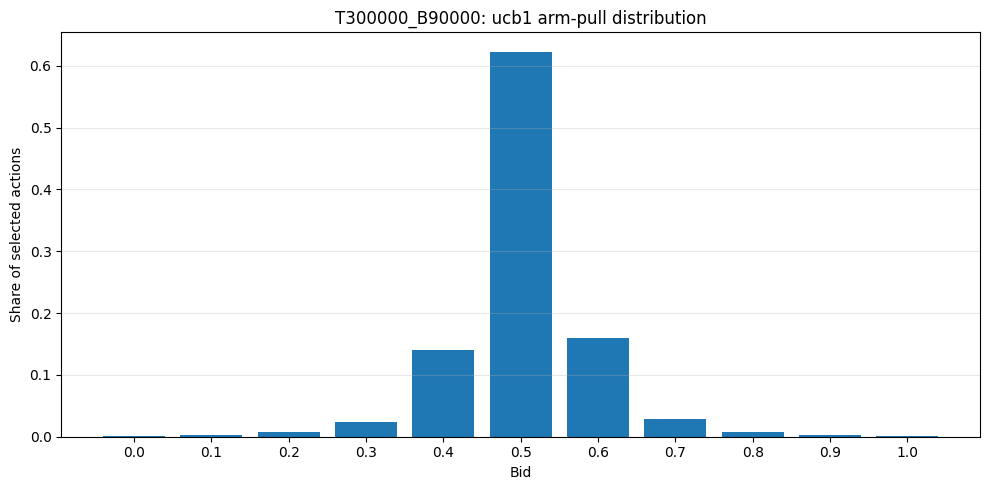

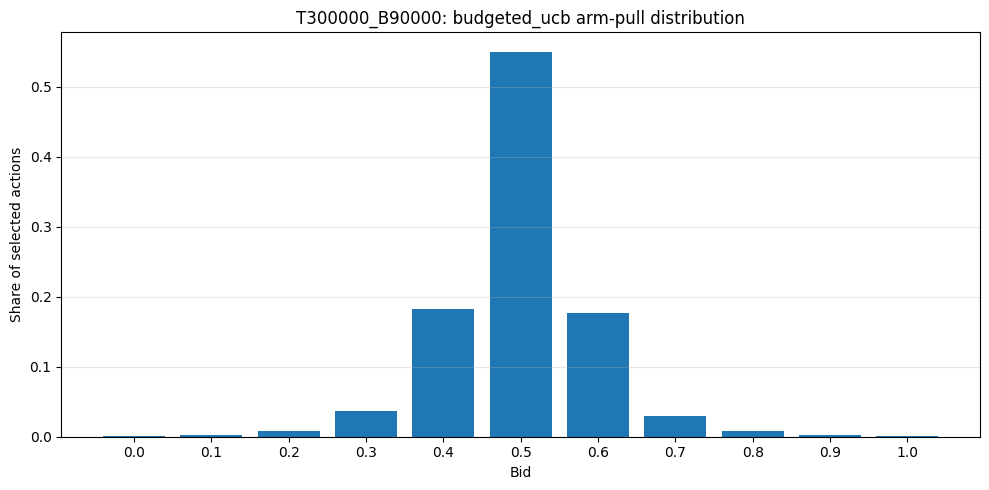

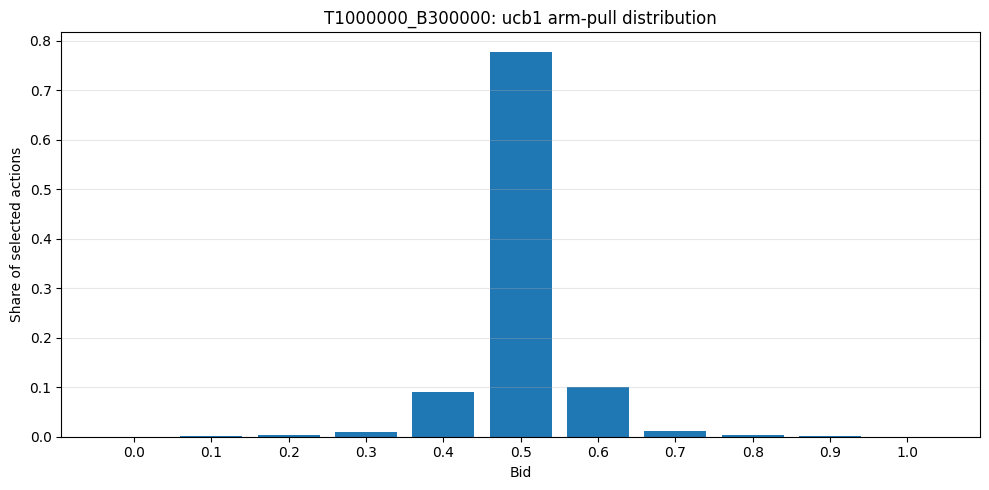

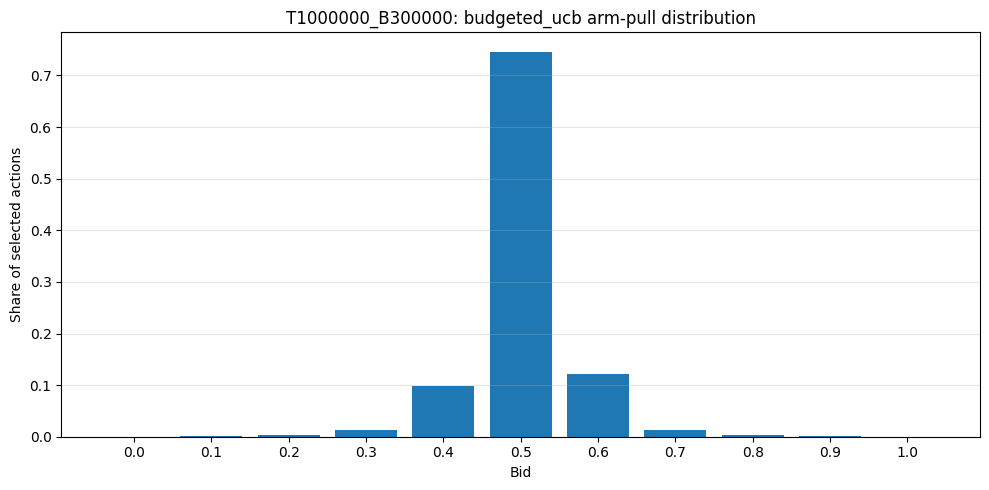

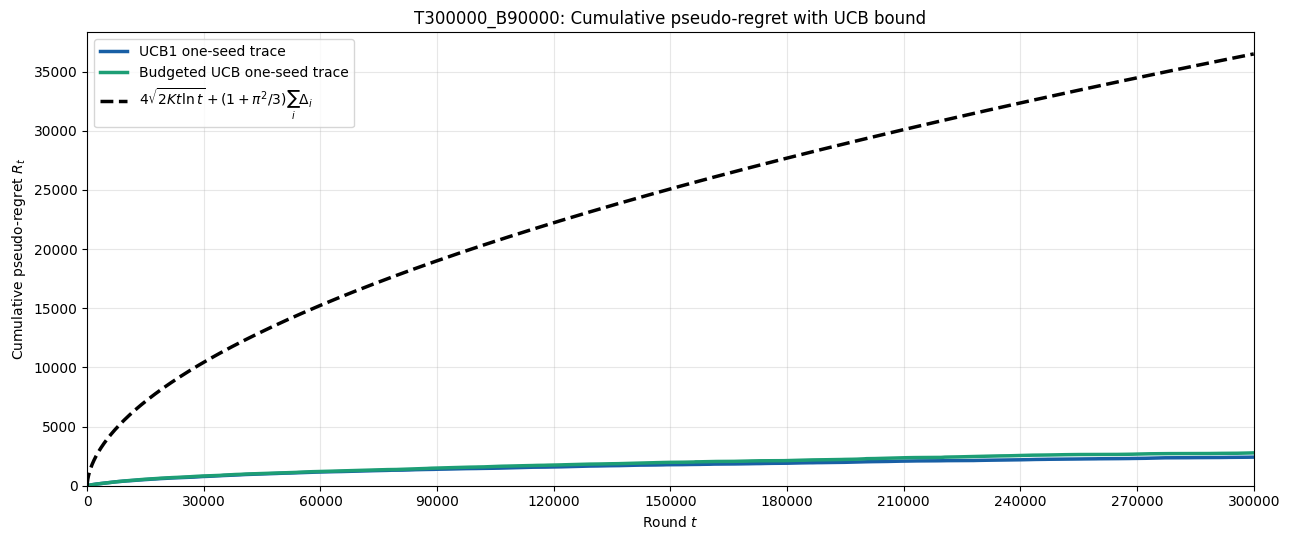

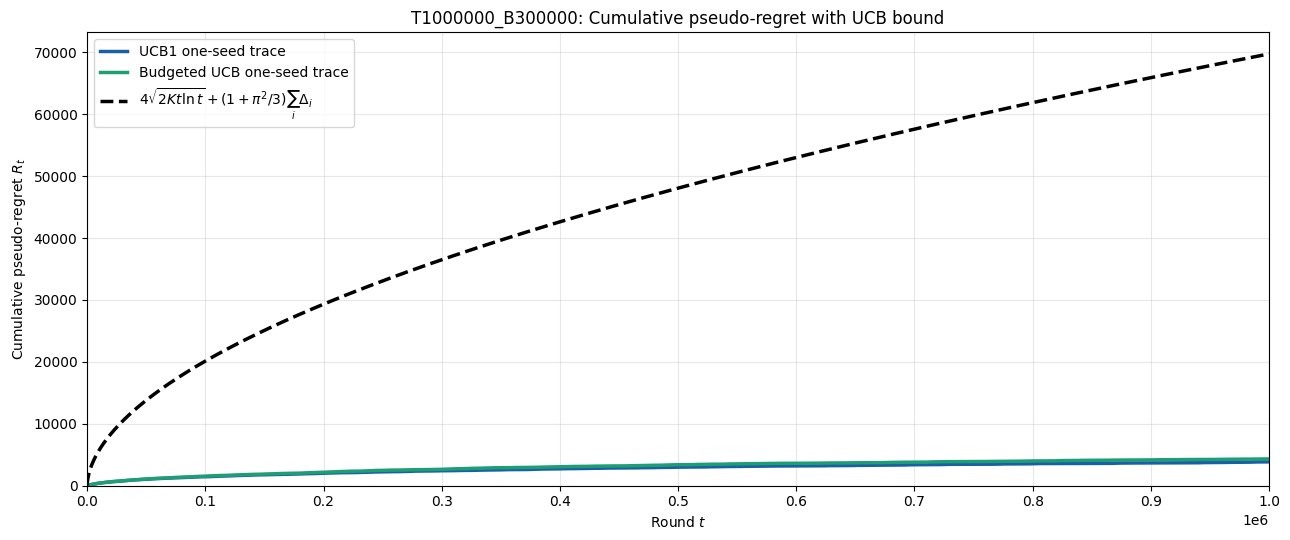

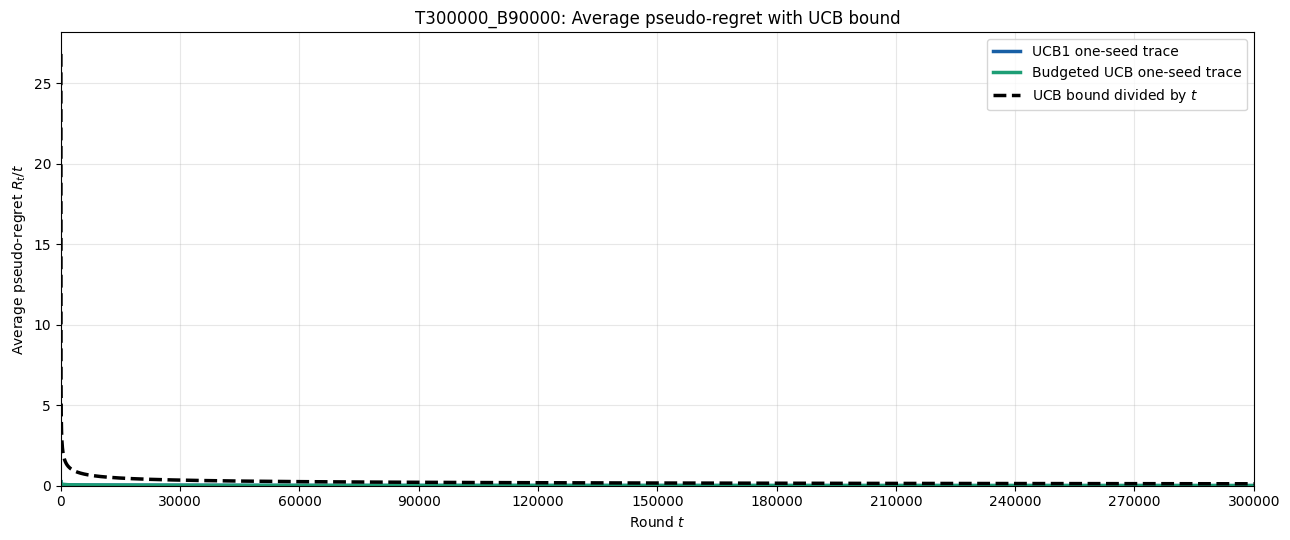

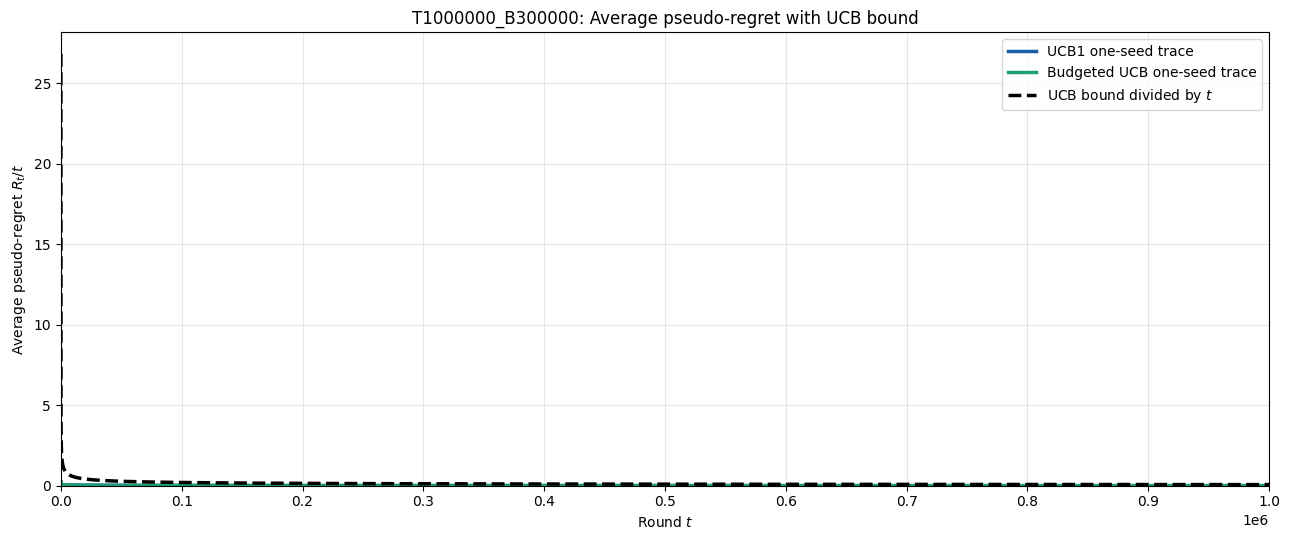

In [54]:
DIAG_SETTINGS = [
    {"horizon": 300_000, "budget": 90_000.0, "label": "T300000_B90000"},
    {"horizon": 1_000_000, "budget": 300_000.0, "label": "T1000000_B300000"},
]

DIAG_SEED = 0


def ucb_gap_free_bound(rounds, bids, value, benchmark_mu):
    rounds = np.asarray(rounds, dtype=float)
    safe_rounds = np.maximum(rounds, 2.0)

    K = len(bids)

    gaps = np.array([
        max(benchmark_mu - expected_reward(b, value), 0.0)
        for b in bids
    ])

    return (
        4.0 * np.sqrt(2.0 * K * safe_rounds * np.log(safe_rounds))
        + (1.0 + (np.pi ** 2) / 3.0) * gaps.sum()
    )


def run_one_seed_diagnostic(
    algorithm_name,
    learner,
    horizon,
    initial_budget,
    random_seed,
):
    env = SingleCampaignEnvironment(
        horizon=horizon,
        initial_budget=initial_budget,
        value=value,
        min_competing_bid=min_competing_bid,
        max_competing_bid=max_competing_bid,
        random_seed=random_seed,
    )

    bench = solve_lp_benchmark(
        bids=bids,
        value=value,
        horizon=horizon,
        initial_budget=initial_budget,
    )

    benchmark_mu = bench["opt"]

    n_actions = len(bids)

    selected_counts = np.zeros(n_actions, dtype=int)
    selected_reward_sums = np.zeros(n_actions, dtype=float)
    selected_cost_sums = np.zeros(n_actions, dtype=float)

    regret_trace = np.zeros(horizon, dtype=float)
    average_regret_trace = np.zeros(horizon, dtype=float)

    cumulative_expected_reward = 0.0
    cumulative_reward = 0.0
    cumulative_cost = 0.0
    last_played_round = 0
    stopped_by_budget = False

    for t in range(1, horizon + 1):
        selected_bid = float(learner.select_action())

        matching_indices = np.where(np.isclose(bids, selected_bid))[0]
        if len(matching_indices) == 0:
            raise ValueError(f"{algorithm_name} selected non-grid bid: {selected_bid}")

        action_index = int(matching_indices[0])

        result = env.step(selected_bid)

        effective_bid = float(result.get("effective_bid", selected_bid))
        reward = float(result["reward"])
        cost = float(result["cost"])

        selected_counts[action_index] += 1
        selected_reward_sums[action_index] += reward
        selected_cost_sums[action_index] += cost

        expected_reward_selected = expected_reward(effective_bid, value)

        cumulative_expected_reward += expected_reward_selected
        cumulative_reward += reward
        cumulative_cost += cost

        cumulative_pseudo_regret = t * benchmark_mu - cumulative_expected_reward

        regret_trace[t - 1] = cumulative_pseudo_regret
        average_regret_trace[t - 1] = cumulative_pseudo_regret / t

        if algorithm_name == "ucb1":
            learner.update(selected_bid, reward)
        else:
            learner.update(selected_bid, reward, cost)

        last_played_round = t

        if t % 100_000 == 0:
            print(
                algorithm_name,
                "round",
                t,
                "budget_left",
                round(result["budget_left"], 2),
                "cum_reward",
                round(cumulative_reward, 2),
                "cum_cost",
                round(cumulative_cost, 2),
                "cum_regret",
                round(cumulative_pseudo_regret, 2),
            )

        if result["done"]:
            if t < horizon:
                stopped_by_budget = True
                print(
                    algorithm_name,
                    "stopped by budget at round",
                    t,
                    "budget_left",
                    round(result["budget_left"], 4),
                )
            else:
                print(
                    algorithm_name,
                    "finished horizon at round",
                    t,
                    "budget_left",
                    round(result["budget_left"], 4),
                )
            break

    if last_played_round < horizon:
        for t in range(last_played_round + 1, horizon + 1):
            cumulative_pseudo_regret = t * benchmark_mu - cumulative_expected_reward
            regret_trace[t - 1] = cumulative_pseudo_regret
            average_regret_trace[t - 1] = cumulative_pseudo_regret / t

    arm_diagnostics = pd.DataFrame({
        "bid": bids,
        "selected_count": selected_counts,
        "selected_share": selected_counts / max(1, selected_counts.sum()),
        "mean_realized_reward_when_selected": np.divide(
            selected_reward_sums,
            np.maximum(1, selected_counts),
        ),
        "mean_realized_cost_when_selected": np.divide(
            selected_cost_sums,
            np.maximum(1, selected_counts),
        ),
        "true_expected_reward": [expected_reward(b, value) for b in bids],
        "true_expected_cost": [expected_cost(b) for b in bids],
    })

    active_benchmark = pd.DataFrame({
        "bid": bench["bids"],
        "probability": bench["dist"],
        "expected_reward": bench["rewards"],
        "expected_cost": bench["costs"],
    })

    active_benchmark = active_benchmark[
        active_benchmark["probability"] > 1e-10
    ].copy()

    summary = {
        "algorithm": algorithm_name,
        "horizon": horizon,
        "initial_budget": initial_budget,
        "rho": initial_budget / horizon,
        "benchmark_reward": benchmark_mu,
        "benchmark_cost": bench["opt_cost"],
        "last_played_round": last_played_round,
        "stopped_by_budget": stopped_by_budget,
        "total_reward": cumulative_reward,
        "total_cost": cumulative_cost,
        "final_budget_left": initial_budget - cumulative_cost,
        "final_pseudo_regret": regret_trace[-1],
        "final_average_pseudo_regret": average_regret_trace[-1],
    }

    return {
        "summary": summary,
        "benchmark": active_benchmark,
        "full_benchmark": bench,
        "arm_diagnostics": arm_diagnostics,
        "regret_trace": regret_trace,
        "average_regret_trace": average_regret_trace,
    }


diag_results = {}

for setting in DIAG_SETTINGS:
    horizon_diag = setting["horizon"]
    budget_diag = setting["budget"]
    label = setting["label"]

    print("=" * 90)
    print("Diagnostic setting:", label)
    print("T:", horizon_diag)
    print("B:", budget_diag)
    print("rho:", budget_diag / horizon_diag)

    ucb1_diag = UCB1(actions=bids, horizon=horizon_diag)

    ucb1_result = run_one_seed_diagnostic(
        algorithm_name="ucb1",
        learner=ucb1_diag,
        horizon=horizon_diag,
        initial_budget=budget_diag,
        random_seed=DIAG_SEED,
    )

    budgeted_diag = BudgetedUCB(
        actions=bids,
        horizon=horizon_diag,
        initial_budget=budget_diag,
    )

    budgeted_result = run_one_seed_diagnostic(
        algorithm_name="budgeted_ucb",
        learner=budgeted_diag,
        horizon=horizon_diag,
        initial_budget=budget_diag,
        random_seed=DIAG_SEED,
    )

    diag_results[label] = {
        "ucb1": ucb1_result,
        "budgeted_ucb": budgeted_result,
        "horizon": horizon_diag,
        "budget": budget_diag,
    }


summary_rows = []

for label, setting_results in diag_results.items():
    for algo in ["ucb1", "budgeted_ucb"]:
        row = setting_results[algo]["summary"].copy()
        row["setting"] = label
        summary_rows.append(row)

diag_summary_df = pd.DataFrame(summary_rows)

display(diag_summary_df[
    [
        "setting",
        "algorithm",
        "horizon",
        "initial_budget",
        "rho",
        "benchmark_reward",
        "benchmark_cost",
        "last_played_round",
        "stopped_by_budget",
        "total_reward",
        "total_cost",
        "final_budget_left",
        "final_pseudo_regret",
        "final_average_pseudo_regret",
    ]
])


for label, setting_results in diag_results.items():
    print("=" * 90)
    print("Benchmark:", label)
    display(setting_results["budgeted_ucb"]["benchmark"])


for label, setting_results in diag_results.items():
    print("=" * 90)
    print("Arm diagnostics:", label)

    for algo in ["ucb1", "budgeted_ucb"]:
        print("-" * 40)
        print(algo)
        display(setting_results[algo]["arm_diagnostics"])


for label, setting_results in diag_results.items():
    for algo in ["ucb1", "budgeted_ucb"]:
        arm_df = setting_results[algo]["arm_diagnostics"]

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            arm_df["bid"].astype(str),
            arm_df["selected_share"],
        )

        ax.set_xlabel("Bid")
        ax.set_ylabel("Share of selected actions")
        ax.set_title(f"{label}: {algo} arm-pull distribution")
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()


for label, setting_results in diag_results.items():
    horizon_diag = setting_results["horizon"]
    rounds = np.arange(1, horizon_diag + 1)

    fig, ax = plt.subplots(figsize=(13, 5.5))

    benchmark_mu = setting_results["ucb1"]["summary"]["benchmark_reward"]

    regret_bound = ucb_gap_free_bound(
        rounds=rounds,
        bids=bids,
        value=value,
        benchmark_mu=benchmark_mu,
    )

    for algo in ["ucb1", "budgeted_ucb"]:
        trace = setting_results[algo]["regret_trace"]
        color = "#185FA5" if algo == "ucb1" else "#1D9E75"
        label_name = "UCB1" if algo == "ucb1" else "Budgeted UCB"

        ax.plot(
            rounds,
            trace,
            label=f"{label_name} one-seed trace",
            color=color,
            lw=2.5,
        )

    ax.plot(
        rounds,
        regret_bound,
        linestyle="--",
        color="black",
        lw=2.5,
        label=r"$4\sqrt{2Kt\ln t} + (1+\pi^2/3)\sum_i \Delta_i$",
    )

    ax.set_xlim(1, horizon_diag)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.linspace(0, horizon_diag, 11))
    ax.set_xlabel("Round $t$")
    ax.set_ylabel("Cumulative pseudo-regret $R_t$")
    ax.set_title(f"{label}: Cumulative pseudo-regret with UCB bound")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()


for label, setting_results in diag_results.items():
    horizon_diag = setting_results["horizon"]
    rounds = np.arange(1, horizon_diag + 1)

    fig, ax = plt.subplots(figsize=(13, 5.5))

    benchmark_mu = setting_results["ucb1"]["summary"]["benchmark_reward"]

    regret_bound = ucb_gap_free_bound(
        rounds=rounds,
        bids=bids,
        value=value,
        benchmark_mu=benchmark_mu,
    )

    average_bound = regret_bound / rounds

    for algo in ["ucb1", "budgeted_ucb"]:
        trace = setting_results[algo]["average_regret_trace"]
        color = "#185FA5" if algo == "ucb1" else "#1D9E75"
        label_name = "UCB1" if algo == "ucb1" else "Budgeted UCB"

        ax.plot(
            rounds,
            trace,
            label=f"{label_name} one-seed trace",
            color=color,
            lw=2.5,
        )

    ax.plot(
        rounds,
        average_bound,
        linestyle="--",
        color="black",
        lw=2.5,
        label=r"UCB bound divided by $t$",
    )

    ax.set_xlim(1, horizon_diag)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.linspace(0, horizon_diag, 11))
    ax.set_xlabel("Round $t$")
    ax.set_ylabel("Average pseudo-regret $R_t/t$")
    ax.set_title(f"{label}: Average pseudo-regret with UCB bound")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()